# North Batten SC-PaCMAP results

This compact notebook follows the current North Batten benchmark style: 30 algorithm seeds, full-population embeddings, K-means at the known lithology count $K=15$, and labels used only for evaluation and plotting.

The notebook keeps the essential data walk-through, one-seed embedding view, three evaluation range plots, the $K=15$ spatialâ€“multivariate performance plane, the cross-hole leave-one-out continuity check. No exports are written.

SC-PaCMAP benchmark runs use `SCPaCMAPConfig()`: positive Geary continuity and the analytical target share, with no configurable cap. In the 30-seed neighbourhood sweep, each embedding neighbourhood $k\in\{10,15,20\}$ is a separate SC-PaCMAP run: its geographic candidate graph uses that same $k$, and the inferred $\lambda_k$ and resulting $k_{S,k}$ are retained in the results table.

**Paper figures:** all plots use consistent sans-serif typography and 600-dpi inline PNG output, with panel letters only, descriptions in captions, and external categorical legends and slim continuous color scales. Copy images directly from their output. Full-width figures are 7.1 inches wide. Plotting cells are separate from computation so they can be rerun with results already in memory. No PNG or PDF files are exported. Each result section has a separate data export cell immediately below it.


**Experiment switch:** `INCLUDE_REPLACEMENT = False` disables the replacement variant in fitting, evaluation, and plots. Set it to `True` in setup to restore the ablation. Figure labels use ?SC-PaCMAP? for the full-graph method. Rerun setup and computation after changing the dataset or switch; existing in-memory results may otherwise describe the previous experiment.


**Saved results.** Run All to save unrounded section data to `results/notebook_exports/<dataset>/<section>/`. Rerunning replaces the named files in that section. CSV files retain seed, method, neighbourhood and cluster-count columns; NumPy archives have JSON key indexes and load with `allow_pickle=False`. Each section includes metadata and colour mappings for later combined paper figures.


In [36]:
from __future__ import annotations
from IPython.display import display
import os, sys
from pathlib import Path

# Keep an already imported kernel's Numba pool size; use one active thread.
# On a fresh kernel, configure the pool before numerical imports.
os.environ['NUMBA_NUM_THREADS'] = str(sys.modules['numba'].config.NUMBA_NUM_THREADS) if 'numba' in sys.modules else '1'
import matplotlib.pyplot as plt
import numba, numpy as np, pandas as pd, seaborn as sns
numba.set_num_threads(1)
import pacmap, umap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
def find_root(start=Path.cwd()):
    for candidate in (start.resolve(),*start.resolve().parents):
        if (candidate/'code'/'sc_pacmap'/'sc_pacmap.py').is_file(): return candidate
        nested=candidate/'sc-pacmap-reproducibility'
        if (nested/'code'/'sc_pacmap'/'sc_pacmap.py').is_file(): return nested
    raise FileNotFoundError('Repository root not found')
ROOT=find_root()
for folder in (ROOT/'code'/'sc_pacmap',ROOT/'code'/'spasne'):
    sys.path.insert(0,str(folder)) if str(folder) not in sys.path else None
from sc_pacmap import PaCMAPSettings, SCPaCMAPConfig, run_legacy_sc_pacmap, run_sc_pacmap
sc_config = SCPaCMAPConfig()
from spasne_adapter import python_spasne
# Keep LocalMAP's Numba resampling reproducible without an external helper file.
import importlib
from contextlib import contextmanager

@numba.njit
def seed_localmap_rng(seed):
    np.random.seed(seed)

@contextmanager
def localmap_seed(seed):
    core = importlib.import_module('pacmap.pacmap')
    original_resample = core.sample_FP_pair_nearby
    call_index = 0
    def seeded_resample(*args, **kwargs):
        nonlocal call_index
        seed_localmap_rng(seed + call_index)
        call_index += 1
        return original_resample(*args, **kwargs)
    seed_localmap_rng(seed)
    core.sample_FP_pair_nearby = seeded_resample
    try:
        yield
    finally:
        core.sample_FP_pair_nearby = original_resample

SEEDS=tuple(range(30)); CROSS_GROUP_SEEDS=tuple(range(30)); N_NEIGHBORS=10; K_REFERENCE=15
data=pd.read_csv(ROOT/'data'/'processed'/'north_batten_sc_pacmap_ready.csv')
FEATURES=[c for c in data.columns if c.endswith(('_PPM','_PCT'))]
coords=data[['x','y','z']].to_numpy(float); truth=data.label_id.to_numpy(int)
features=StandardScaler().fit_transform(data[FEATURES]).astype(np.float32); xyz=StandardScaler().fit_transform(coords); features_xyz=np.column_stack([features,xyz])
tss=float(np.sum((features-features.mean(0,keepdims=True))**2)); spatial_neighbors=NearestNeighbors(n_neighbors=N_NEIGHBORS+1,n_jobs=1).fit(coords).kneighbors(coords,return_distance=False)[:,1:]
settings_base=dict(n_components=2,n_neighbors=N_NEIGHBORS,mn_ratio=.5,fp_ratio=2.,learning_rate=1.,num_iters=(100,100,250),knn_backend='faiss',verbose=False)
ALL_METHODS = ['UMAP + XYZ','PaCMAP + XYZ','LocalMAP + XYZ','PaCMAP feature-only','SC-PaCMAP replacement','SC-PaCMAP full graph','SpaSNE']
INCLUDE_REPLACEMENT = False  # Enable only when running the replacement ablation.
METHODS = [m for m in ALL_METHODS if INCLUDE_REPLACEMENT or m != "SC-PaCMAP replacement"]
print(f'{len(data)} intervals | {len(FEATURES)} features | {data.group_id.nunique()} drillholes | K={K_REFERENCE}')
K_VALUES = range(2, 16)
MARKERS = dict(zip(ALL_METHODS, ['o', '^', 'v', 'P', 'h', '*', 'X']))
NEIGHBOR_VALUES = (10, 15, 20)  # Embedding neighborhoods in stability/cloud sections only
DATASET_TITLE = 'North Batten'


# Publication defaults: full-paper-width figures, 600-dpi inline PNG, no exports.
from matplotlib_inline.backend_inline import set_matplotlib_formats
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
set_matplotlib_formats('png')
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'], 'mathtext.fontset': 'dejavusans',
    'font.size': 8, 'axes.titlesize': 8, 'figure.titlesize': 10, 'figure.titleweight': 'normal',
    'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'legend.title_fontsize': 7,
    'figure.dpi': 600, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': '#444444', 'axes.linewidth': .6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False,
    'grid.color': '#E4E4E4', 'grid.linewidth': .45,
    'xtick.major.size': 3, 'ytick.major.size': 3,
    'xtick.major.width': .6, 'ytick.major.width': .6,
    'lines.linewidth': 1.1, 'lines.markersize': 3,
    'legend.frameon': False, 'figure.constrained_layout.h_pad': .06,
    'figure.constrained_layout.w_pad': .06,
})
# Stable named mappings keep colors unchanged when the ablation is toggled.
COLORS = dict(zip(ALL_METHODS, ['#4477AA', '#66AABB', '#228833', '#AA8855', '#AA3377', '#BB4455', '#666666']))
METHOD_LABELS = {m: ('SC-PaCMAP' if m == 'SC-PaCMAP full graph' else m) for m in ALL_METHODS}
# Paul Tol's colour-blind-safe muted palette, distinct from method colours.
# Source: https://sronpersonalpages.nl/~pault/#sec:qualitative
CLASS_IDS = np.unique(truth)
# Exclude indigo and teal: those colours identify ClustGeo methods.
CLASS_BASE_PALETTE = ['#DDCC77', '#88CCEE', '#117733', '#999933',
                      '#882255', '#AA4499', '#CC6677']
# Repeated colours receive different shapes when there are >7 classes.
CLASS_SHAPES = ('o', '^', 's')
if len(CLASS_IDS) > len(CLASS_BASE_PALETTE) * len(CLASS_SHAPES):
    raise ValueError('Add distinguishable class encodings before plotting more than 21 classes.')
CLASS_PALETTE = [CLASS_BASE_PALETTE[i % len(CLASS_BASE_PALETTE)] for i in range(len(CLASS_IDS))]
CLASS_MARKERS = [CLASS_SHAPES[i // len(CLASS_BASE_PALETTE)] for i in range(len(CLASS_IDS))]
CLASS_CMAP = ListedColormap(CLASS_PALETTE[:len(CLASS_IDS)])
CLASS_NORM = BoundaryNorm(np.arange(len(CLASS_IDS) + 1) - .5, len(CLASS_IDS))
CLASS_INDEX = np.searchsorted(CLASS_IDS, truth)
if 'LABEL_deposit_group' in data:
    names = data.drop_duplicates('label_id').set_index('label_id')['LABEL_deposit_group']
    CLASS_LABELS = [str(names.loc[label]) for label in CLASS_IDS]
elif 'label_lithology' in data:
    names = data.drop_duplicates('label_id').set_index('label_id')['label_lithology']
    CLASS_LABELS = [str(names.loc[label]).split(' - ')[0].strip() for label in CLASS_IDS]
else:
    CLASS_LABELS = [f'Facies {chr(65 + i)}' for i in range(len(CLASS_IDS))]

def class_scatter(ax, x, y, **kwargs):
    # Colour and marker mappings match the class legend in every panel.
    x, y = np.asarray(x), np.asarray(y)
    for i in range(len(CLASS_IDS)):
        mask = CLASS_INDEX == i
        ax.scatter(x[mask], y[mask], color=CLASS_PALETTE[i],
                   marker=CLASS_MARKERS[i], **kwargs)

def class_legend(fig, ax=None):
    handles = [Line2D([], [], marker=CLASS_MARKERS[i], linestyle='None',
                      markerfacecolor=CLASS_PALETTE[i], markeredgecolor='none',
                      markersize=4, label=label) for i, label in enumerate(CLASS_LABELS)]
    if ax is not None:
        return ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, -.30),
                         ncol=2, handletextpad=.3, columnspacing=.8, borderaxespad=0)
    columns = 5 if len(handles) > 9 else (4 if len(handles) <= 4 else 3)
    return fig.legend(handles=handles, loc='outside lower center', ncol=columns,
                      handletextpad=.35, columnspacing=1.3, labelspacing=.45)

def paper_show(fig):
    # One high-resolution copyable image, without creating files on disk.
    display(fig)
    plt.close(fig)


3222 intervals | 46 features | 22 drillholes | K=15


In [37]:
# Data-only export setup. Run All saves each section below its result cell.
import json
from dataclasses import asdict
from importlib.metadata import version, PackageNotFoundError
if str(ROOT / 'code') not in sys.path:
    sys.path.insert(0, str(ROOT / 'code'))
from notebook_result_export import export_section
SOURCE_NOTEBOOK = '02_north_batten_sc_pacmap_results.ipynb'
EXPORT_ROOT = ROOT / 'results' / 'notebook_exports'
DATASET_ID = DATASET_TITLE.lower().replace(' ', '_')

def save_section(section, *, tables=None, arrays=None, stores=None):
    packages = {}
    for package in ('numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'pacmap', 'umap-learn'):
        try:
            packages[package] = version(package)
        except PackageNotFoundError:
            packages[package] = 'not installed'
    metadata = {
        'dataset_title': DATASET_TITLE, 'source_notebook': SOURCE_NOTEBOOK,
        'K_reference': K_REFERENCE, 'embedding_neighbors': list(NEIGHBOR_VALUES),
        'evaluation_neighbors': int(spatial_neighbors.shape[1]),
        'seeds': list(SEEDS), 'reference_seed': 0,
        'data_seed': globals().get('DATA_SEED'),
        'include_replacement': INCLUDE_REPLACEMENT, 'methods': list(METHODS),
        'feature_columns': list(FEATURES), 'sample_count': len(data),
        'sample_order': 'Zero-based row order of data_walkthrough/data.csv',
        'method_colors': COLORS, 'method_labels': METHOD_LABELS,
        'method_markers': MARKERS,
        'class_ids': CLASS_IDS.tolist(), 'class_labels': CLASS_LABELS,
        'class_colors': CLASS_PALETTE, 'class_markers': CLASS_MARKERS,
        'pacmap_settings': settings_base, 'sc_pacmap_config': asdict(sc_config),
        'package_versions': packages,
        'score_definitions': {
            'spatial_contiguity': '100 * (1 - H_per_sample / log(min(K, evaluation_neighbors)))',
            'multivariate_delineation': '100 * (1 - WCSS_TSS)',
            'paired_delta': 'SC-PaCMAP full graph minus comparator',
        },
        'inference_unit': 'Algorithm seed on one fixed dataset',
        'metric_test': {'alternative': 'two-sided', 'correction': 'Holm across dataset metrics, baselines and neighbourhoods',
                        'alpha': globals().get('STAT_ALPHA', .05),
                        'permutation_resamples': globals().get('STAT_RESAMPLES'),
                        'bootstrap_resamples': globals().get('STAT_BOOTSTRAPS'),
                        'random_seed': globals().get('STAT_RANDOM_SEED')},
        'continuity_test': {'alternative': 'greater', 'correction': 'Holm across dataset comparators'},
    }
    return export_section(EXPORT_ROOT, DATASET_ID, section,
                          metadata=metadata, tables=tables, arrays=arrays, stores=stores)
print(f'Section data exports: {EXPORT_ROOT / DATASET_ID}')


Section data exports: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten


### Reference fit and evaluation helpers

Fit the reference embeddings needed for graph diagnostics; group IDs are used only for evaluation.


In [ ]:
def fit_embeddings(seed, feature_values=features, coordinate_values=coords, *,
                   n_neighbors=N_NEIGHBORS, spasne_embedding=None):
    numba.set_num_threads(1)
    features_with_coordinates = np.column_stack([feature_values, StandardScaler().fit_transform(coordinate_values)])
    settings=PaCMAPSettings(random_state=seed, **{**settings_base, 'n_neighbors': n_neighbors}); args={'n_components':2,'n_neighbors':n_neighbors,'MN_ratio':.5,'FP_ratio':2.,'distance':'euclidean','lr':1.,'num_iters':(100,100,250),'apply_pca':True,'random_state':seed,'save_tree':False,'knn_backend':'faiss'}; out={}
    out['UMAP + XYZ']=umap.UMAP(n_neighbors=n_neighbors,n_components=2,metric='euclidean',learning_rate=1.,random_state=seed,n_jobs=1).fit_transform(features_with_coordinates)
    out['PaCMAP + XYZ']=pacmap.PaCMAP(**args).fit_transform(features_with_coordinates,init='pca',save_pairs=False)
    with localmap_seed(seed):
        out['LocalMAP + XYZ']=pacmap.LocalMAP(**{**args,'low_dist_thres':10}).fit_transform(np.ascontiguousarray(features_with_coordinates, dtype=np.float64),init='pca',save_pairs=False)
    out['PaCMAP feature-only']=pacmap.PaCMAP(**args).fit_transform(feature_values,init='pca',save_pairs=False)
    if INCLUDE_REPLACEMENT:
        r,_=run_legacy_sc_pacmap(feature_values,coordinate_values,settings); out['SC-PaCMAP replacement']=r.embedding
    r,d=run_sc_pacmap(feature_values,coordinate_values,settings, config=sc_config); out['SC-PaCMAP full graph']=r.embedding
    if spasne_embedding is None:
        out['SpaSNE']=python_spasne(feature_values,coordinate_values,random_state=seed,alpha=10.,beta=5.,exaggeration=4,perplexity=50,theta=.5,max_iter=1000,use_pca=True,spasne_dir=ROOT/'code'/'spasne'/'spasne_original')
    else:
        out['SpaSNE'] = spasne_embedding
    return out,d


def entropy(labels, neighbors=spatial_neighbors):
    total = 0.
    for n in neighbors:
        counts = np.bincount(labels[n])
        p = counts[counts > 0] / neighbors.shape[1]
        total -= float(np.sum(p * np.log(p)))
    return total / len(labels)


def wcss(labels, k=K_REFERENCE, feature_values=features, total_ss=tss):
    centers = np.vstack([feature_values[labels == j].mean(0) for j in range(k)])
    return float(np.sum((feature_values - centers[labels])**2)) / total_ss


def evaluate(labels, k, feature_values=features, neighbors=spatial_neighbors,
             label_truth=truth, total_ss=tss):
    return {'H_per_sample': entropy(labels, neighbors),
            'WCSS_TSS': wcss(labels, k, feature_values, total_ss),
            'ARI': adjusted_rand_score(label_truth, labels)}

one_seed_embeddings, one_seed_diag = fit_embeddings(0)
# Convert stored embeddings to float64 before K-means evaluation.
one_seed_embeddings = {m: np.asarray(y, dtype=np.float64) for m, y in one_seed_embeddings.items()}
one_seed_rows = []
one_seed_clusters = {}
for method in METHODS:
    embedding = one_seed_embeddings[method]
    cluster_labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                            random_state=1000 + K_REFERENCE).fit_predict(embedding)
    one_seed_clusters[method] = cluster_labels.copy()
    one_seed_rows.append({'method': method, 'K': K_REFERENCE, **evaluate(cluster_labels, K_REFERENCE)})
one_seed_results = pd.DataFrame(one_seed_rows)
display(one_seed_results.round(4))
print(f'Automatic spatial-strength lambda: {one_seed_diag.spatial_strength_lambda:.3f}')


In [ ]:
# Export this section as data for later paper figures.
# Save unrounded seed-0 metrics and embeddings, with sample order preserved.
save_section('one_seed', tables={'metrics': one_seed_results},
             stores={'embeddings': (one_seed_embeddings, ['method']),
                     'clusters': (one_seed_clusters, ['method'])})


## Data walk-through

Lithology is evaluation-only. The drillhole field is retained for the cross-hole continuity check, while standardized geochemistry and optional standardized XYZ are the embedding inputs.

,label_id,label_lithology,intervals
0,0,BXZN - Breccia Zone,27
1,1,LSR - Saprock,32
2,2,SAN - Arenite,24
3,3,SCH - Carbonaceous Shale,47
4,4,SDE - Dolarenite; coarse grained dolostone,28
5,5,SDH - Dolomitic Shale,201
6,6,SDL - Laminated Dolomite,20
7,7,SDM - Stromatolitic Dolomite,33
8,8,SDO - Dolomite,299
9,9,SIH - Interbedded siltstone/shale,65


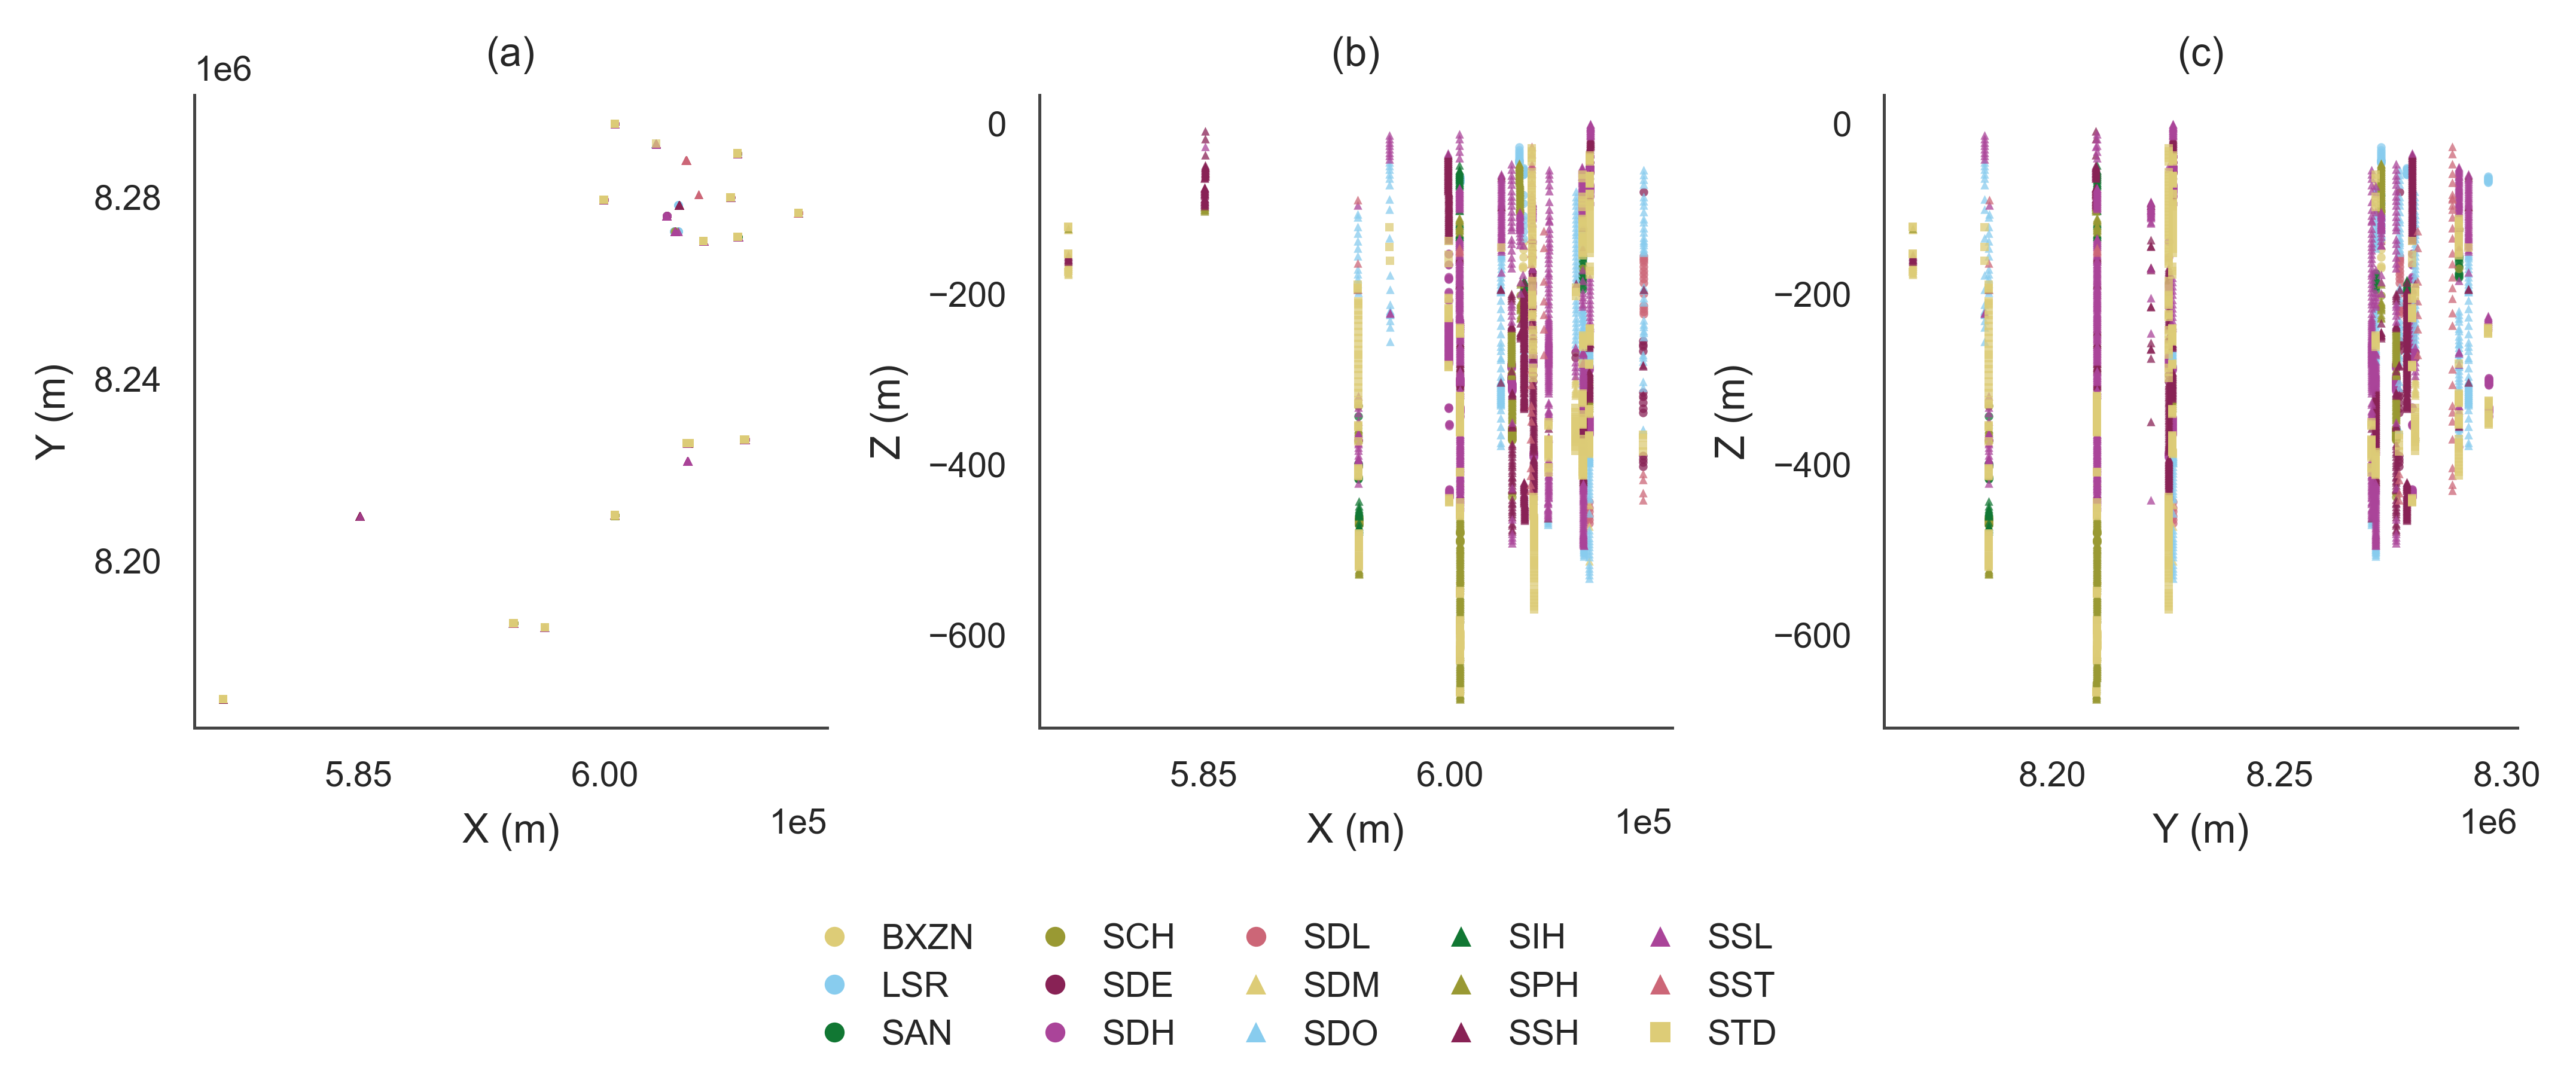

In [40]:
from IPython.display import display

display(data.groupby(['label_id','label_lithology'],observed=True).size().rename('intervals').reset_index())

fig, axes = plt.subplots(1, 3, figsize=(7.1, 3.05), layout='constrained')
for index, (ax, pair) in enumerate(zip(axes, [('x', 'y'), ('x', 'z'), ('y', 'z')])):
    class_scatter(ax, data[pair[0]], data[pair[1]], s=3, alpha=.75, linewidths=0)
    ax.set(xlabel=f'{pair[0].upper()} (m)', ylabel=f'{pair[1].upper()} (m)',
           title=f'({chr(97 + index)})')
    ax.set_box_aspect(1)
    ax.ticklabel_format(style='sci', axis='both', scilimits=(-3, 4), useOffset=False)
    ax.xaxis.set_major_locator(MaxNLocator(3))
    ax.yaxis.set_major_locator(MaxNLocator(4))
class_legend(fig)
paper_show(fig)


In [41]:
# Export this section as data for later paper figures.
save_section('data_walkthrough',
             tables={'data': data.reset_index(drop=True).rename_axis('sample_index').reset_index()},
             arrays={'coordinates': coords, 'truth': truth,
                     'standardized_features': features, 'spatial_neighbors': spatial_neighbors})


Saved 2 data artifacts: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten\data_walkthrough


WindowsPath('C:/Users/weihong/Desktop/SC-PACMAP/sc-pacmap-reproducibility/results/notebook_exports/north_batten/data_walkthrough')

**Figure caption.** North Batten spatial distribution. (a) XY; (b) XZ; (c) YZ. Coordinates are in metres. Lithology colours use [Paul Tol's colour-blind-safe muted palette](https://sronpersonalpages.nl/~pault/#sec:qualitative). The 15 lithologies use distinct colour-and-marker combinations: the seven colours are reused with circles, triangles, and squares; colour alone does not identify every lithology.


## One seed: embeddings and K=15 evaluation

Each panel colors the raw 2-D embedding by the evaluation-only true label. K-means
still evaluates the same embedding at $K=15$ for the result table below. Cluster IDs
do not correspond between methods, and ground-truth labels are used only for plotting
and the ARI in the result table.

In [ ]:

ncols = 3 if len(METHODS) <= 6 else 4
fig, axes = plt.subplots(2, ncols, figsize=(7.1, 5.15), layout='constrained')
for index, (ax, method) in enumerate(zip(axes.flat, METHODS)):
    embedding = one_seed_embeddings[method]
    class_scatter(ax, embedding[:, 0], embedding[:, 1], s=2.5, alpha=.8, linewidths=0)
    ax.set_title(f'({chr(97 + index)})')
    ax.set_aspect('equal', adjustable='datalim')
    ax.set_box_aspect(1)
    # Embedding orientation and absolute coordinate values have no physical units.
    ax.set_xticks([])
    ax.set_yticks([])
for unused_ax in list(axes.flat)[len(METHODS):]:
    unused_ax.set_visible(False)
class_legend(fig)
# An axes label participates in layout above the external legend.
label_ax = axes[-1, (ncols - 1) // 2]
label_ax.set_xlabel('Embedding dimension 1', labelpad=8)
fig.supylabel('Embedding dimension 2')
paper_show(fig)


In [ ]:
# Export this section as data for later paper figures.
# Save unrounded seed-0 metrics and embeddings, with sample order preserved.
save_section('one_seed', tables={'metrics': one_seed_results},
             stores={'embeddings': (one_seed_embeddings, ['method']),
                     'clusters': (one_seed_clusters, ['method'])})


**Figure caption.** North Batten embedding comparison (seed 0), coloured by evaluation-only lithology labels. Panels in reading order: (a) UMAP + XYZ; (b) PaCMAP + XYZ; (c) LocalMAP + XYZ; (d) PaCMAP feature-only; (e) SC-PaCMAP; (f) SpaSNE. This mapping is for `INCLUDE_REPLACEMENT=False`; when the ablation is enabled, (e) is SC-PaCMAP replacement, (f) is SC-PaCMAP, and (g) is SpaSNE. Each embedding has its own coordinate range and arbitrary orientation; axes are independently scaled and oriented. Absolute distances and apparent cluster separation must not be compared across panels by visual scale. Lithology colours use [Paul Tol's colour-blind-safe muted palette](https://sronpersonalpages.nl/~pault/#sec:qualitative). The 15 lithologies use distinct colour-and-marker combinations: the seven colours are reused with circles, triangles, and squares; colour alone does not identify every lithology.


## Thirty-seed evaluation curves: neighborhood robustness

Embedding neighborhood sizes **10, 15, and 20** use the same **30 algorithm seeds (0?29)** on the same full dataset. The figure has one row per neighborhood size and one column per metric. Lines show seed medians; shading shows observed seed min?max ranges, not confidence intervals. Results are kept separate by neighborhood size, rather than pooled into a 90-run band.

Lowercase neighborhood size is distinct from **K**, the K-means cluster count swept along the horizontal axis. The reference line marks the dataset's true class count. K-means uses raw 2-D embeddings, 20 initializations, and a fixed clustering seed for each K. The geographic evaluation window remains **10 neighbors** in every panel so entropy measures the same spatial scale.

The neighborhood setting changes UMAP, PaCMAP, LocalMAP, and both SC-PaCMAP variants together. SpaSNE has no equivalent n_neighbors parameter: its perplexity stays at 50, and each seed's result is reused across rows as the same baseline. SC-PaCMAP uses the uncapped analytical target share throughout.

One-seed embeddings and cross-group/deposit checks retain the default neighborhood size 10. This sweep tests sensitivity to neighborhood choice; it does not by itself guarantee stronger performance.

In the figure, rows identify embedding neighborhood size and columns identify metrics. Lower entropy and WCSS/TSS are better; higher ARI is better. Dotted lines mark the reference class count.


In [44]:
benchmark_methods = [method for method in METHODS if method not in globals().get('CLUSTGEO_ALPHA_BY_METHOD', {})]
benchmark_embeddings, benchmark_clusters = {}, {}
sc_diagnostics = {}
rows = []
for seed in SEEDS:
    # SpaSNE uses fixed perplexity=50, with no n_neighbors parameter.
    # Reuse that seed's baseline across neighborhood panels, not as independent runs.
    spasne_embedding = None
    for n_neighbors in NEIGHBOR_VALUES:
        embeddings, diagnostics = fit_embeddings(seed, n_neighbors=n_neighbors,
                                       spasne_embedding=spasne_embedding)
        spasne_embedding = embeddings['SpaSNE']
        # n_neighbors also defines SC-PaCMAP's geographic candidate graph.
        sc_diagnostics[(seed, n_neighbors)] = {
            'lambda_inferred': float(diagnostics.spatial_strength_lambda),
            'k_S': int(diagnostics.k_spatial),
        }
        for method in benchmark_methods:
            embedding = np.asarray(embeddings[method], dtype=np.float64)
            benchmark_embeddings[(seed, n_neighbors, method)] = embedding
            for k in K_VALUES:
                labels = KMeans(n_clusters=k, init='k-means++', n_init=20,
                                random_state=1000 + k).fit_predict(embedding)
                benchmark_clusters[(seed, n_neighbors, method, k)] = labels.copy()
                sc_values = (sc_diagnostics[(seed, n_neighbors)]
                             if method == 'SC-PaCMAP full graph'
                             else {'lambda_inferred': np.nan, 'k_S': np.nan})
                rows.append({'seed': seed, 'n_neighbors': n_neighbors,
                             'method': method, 'K': k, **sc_values, **evaluate(labels, k)})
        print(f'Completed algorithm seed {seed}, n_neighbors={n_neighbors}', flush=True)
results = pd.DataFrame(rows)
range_results = results
assert len(results) == len(SEEDS) * len(NEIGHBOR_VALUES) * len(benchmark_methods) * len(K_VALUES)
assert not results.duplicated(['seed', 'n_neighbors', 'method', 'K']).any()
assert results.groupby(['n_neighbors', 'method', 'K']).seed.nunique().eq(len(SEEDS)).all()
assert np.isfinite(results[['H_per_sample', 'WCSS_TSS', 'ARI']].to_numpy()).all()
assert len(sc_diagnostics) == len(SEEDS) * len(NEIGHBOR_VALUES)
assert results.loc[results.method == 'SC-PaCMAP full graph', ['lambda_inferred', 'k_S']].notna().all().all()
assert len(benchmark_embeddings) == len(SEEDS) * len(NEIGHBOR_VALUES) * len(benchmark_methods)
assert len(benchmark_clusters) == len(benchmark_embeddings) * len(K_VALUES)



Completed algorithm seed 0, n_neighbors=10


Completed algorithm seed 0, n_neighbors=15


Completed algorithm seed 0, n_neighbors=20


Completed algorithm seed 1, n_neighbors=10


Completed algorithm seed 1, n_neighbors=15


...

Completed algorithm seed 28, n_neighbors=15


Completed algorithm seed 28, n_neighbors=20


Completed algorithm seed 29, n_neighbors=10


Completed algorithm seed 29, n_neighbors=15


Completed algorithm seed 29, n_neighbors=20


In [45]:
# Export this section as data for later paper figures.
save_section('benchmark', tables={'seed_metrics': results},
             stores={'embeddings': (benchmark_embeddings, ['seed', 'n_neighbors', 'method']),
                     'clusters': (benchmark_clusters, ['seed', 'n_neighbors', 'method', 'K'])})


Saved 5 data artifacts: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten\benchmark


WindowsPath('C:/Users/weihong/Desktop/SC-PACMAP/sc-pacmap-reproducibility/results/notebook_exports/north_batten/benchmark')

## PaCMAP feature-only + ClustGeo benchmark

Thirty feature-only PaCMAP embeddings at every benchmark neighbourhood, clustered with ClustGeo at alpha = 0, 0.5, and 1.


In [46]:
if str(ROOT / 'code') not in sys.path: sys.path.insert(0, str(ROOT / 'code'))
from clustgeo_benchmark import clustgeo_partitions
if 'benchmark_clusters' not in globals():
    raise RuntimeError('Run the 30-seed benchmark cell first; ClustGeo reuses its artifact store.')

CLUSTGEO_ALPHAS = (0., .5, 1.)
clustgeo_rows, clustgeo_labels = [], {}
for n_neighbors in NEIGHBOR_VALUES:
    for seed in SEEDS:
        embedding = benchmark_embeddings[(seed, n_neighbors, 'PaCMAP feature-only')]
        for k in K_VALUES:
            for alpha, labels in clustgeo_partitions(embedding, coords, k, CLUSTGEO_ALPHAS):
                clustgeo_labels[(n_neighbors, seed, alpha, k)] = labels
                clustgeo_rows.append({'seed': seed, 'n_neighbors': n_neighbors, 'alpha': alpha,
                                      'K': k, **evaluate(labels, k)})
        print(f'Completed ClustGeo seed {seed}, n_neighbors={n_neighbors}', flush=True)

clustgeo_results = pd.DataFrame(clustgeo_rows)
assert len(clustgeo_results) == len(SEEDS) * len(NEIGHBOR_VALUES) * len(CLUSTGEO_ALPHAS) * len(K_VALUES)
assert clustgeo_results.groupby(['n_neighbors', 'alpha', 'K']).seed.nunique().eq(len(SEEDS)).all()
CLUSTGEO_METHODS = {alpha: f'PaCMAP feature-only + ClustGeo (alpha={alpha:g})' for alpha in CLUSTGEO_ALPHAS}
CLUSTGEO_ALPHA_BY_METHOD = {method: alpha for alpha, method in CLUSTGEO_METHODS.items()}
for (n_neighbors, seed, alpha, k), labels in clustgeo_labels.items():
    benchmark_clusters[(seed, n_neighbors, CLUSTGEO_METHODS[alpha], k)] = labels
clustgeo_results['method'] = clustgeo_results.alpha.map(CLUSTGEO_METHODS)
base_methods = [method for method in METHODS if method not in CLUSTGEO_ALPHA_BY_METHOD]
METHODS = base_methods + list(CLUSTGEO_ALPHA_BY_METHOD)
COLORS.update(dict(zip(CLUSTGEO_ALPHA_BY_METHOD, ['#332288', '#44AA99', '#CCBB44'])))
MARKERS.update(dict(zip(CLUSTGEO_ALPHA_BY_METHOD, ['X', 'D', 's'])))
METHOD_LABELS.update({method: method.replace('alpha=', 'alpha = ') for method in CLUSTGEO_ALPHA_BY_METHOD})
results = pd.concat([results.loc[~results.method.isin(CLUSTGEO_ALPHA_BY_METHOD)], clustgeo_results], ignore_index=True)
range_results = results
display(clustgeo_results.loc[clustgeo_results.K == K_REFERENCE].groupby(['n_neighbors', 'method'])[['H_per_sample', 'WCSS_TSS', 'ARI']].agg(['mean', 'std']).round(4))


Completed ClustGeo seed 0, n_neighbors=10
Completed ClustGeo seed 1, n_neighbors=10
Completed ClustGeo seed 2, n_neighbors=10
Completed ClustGeo seed 3, n_neighbors=10
Completed ClustGeo seed 4, n_neighbors=10
Completed ClustGeo seed 5, n_neighbors=10
Completed ClustGeo seed 6, n_neighbors=10
Completed ClustGeo seed 7, n_neighbors=10
Completed ClustGeo seed 8, n_neighbors=10
Completed ClustGeo seed 9, n_neighbors=10
Completed ClustGeo seed 10, n_neighbors=10
Completed ClustGeo seed 11, n_neighbors=10
Completed ClustGeo seed 12, n_neighbors=10
Completed ClustGeo seed 13, n_neighbors=10
Completed ClustGeo seed 14, n_neighbors=10
Completed ClustGeo seed 15, n_neighbors=10
Completed ClustGeo seed 16, n_neighbors=10
Completed ClustGeo seed 17, n_neighbors=10
Completed ClustGeo seed 18, n_neighbors=10
Completed ClustGeo seed 19, n_neighbors=10
Completed ClustGeo seed 20, n_neighbors=10
Completed ClustGeo seed 21, n_neighbors=10
Completed ClustGeo seed 22, n_neighbors=10
Completed ClustGeo se

H_per_sample          \
                                                               mean     std   
n_neighbors method                                                            
10          PaCMAP feature-only + ClustGeo (alpha=0)         0.5585  0.0207   
            PaCMAP feature-only + ClustGeo (alpha=0.5)       0.2906  0.0221   
            PaCMAP feature-only + ClustGeo (alpha=1)         0.0000  0.0000   
15          PaCMAP feature-only + ClustGeo (alpha=0)         0.6298  0.0187   
            PaCMAP feature-only + ClustGeo (alpha=0.5)       0.3278  0.0182   
            PaCMAP feature-only + ClustGeo (alpha=1)         0.0000  0.0000   
20          PaCMAP feature-only + ClustGeo (alpha=0)         0.6497  0.0156   
            PaCMAP feature-only + ClustGeo (alpha=0.5)       0.3466  0.0195   
            PaCMAP feature-only + ClustGeo (alpha=1)         0.0000  0.0000   

                                                       WCSS_TSS          \
                                                           mean     std   
n_neighbors method                                                        
10          PaCMAP feature-only + ClustGeo (alpha=0)     0.6027  0.0078   
            PaCMAP feature-only + ClustGeo (alpha=0.5)   0.6646  0.0091   
            PaCMAP feature-only + ClustGeo (alpha=1)     0.8566  0.0000   
15          PaCMAP feature-only + ClustGeo (alpha=0)     0.5886  0.0093   
            PaCMAP feature-only + ClustGeo (alpha=0.5)   0.6544  0.0121   
            PaCMAP feature-only + ClustGeo (alpha=1)     0.8566  0.0000   
20          PaCMAP feature-only + ClustGeo (alpha=0)     0.5834  0.0099   
            PaCMAP feature-only + ClustGeo (alpha=0.5)   0.6458  0.0086   
            PaCMAP feature-only + ClustGeo (alpha=1)     0.8566  0.0000   

                                                           ARI          
                                                          mean     std  
n_neighbors method                                                      
10          PaCMAP feature-only + ClustGeo (alpha=0)    0.1157  0.0085  
            PaCMAP feature-only + ClustGeo (alpha=0.5)  0.1133  0.0048  
            PaCMAP feature-only + ClustGeo (alpha=1)    0.1287  0.0000  
15          PaCMAP feature-only + ClustGeo (alpha=0)    0.0978  0.0063  
            PaCMAP feature-only + ClustGeo (alpha=0.5)  0.1085  0.0059  
            PaCMAP feature-only + ClustGeo (alpha=1)    0.1287  0.0000  
20          PaCMAP feature-only + ClustGeo (alpha=0)    0.0968  0.0042  
            PaCMAP feature-only + ClustGeo (alpha=0.5)  0.1037  0.0030  
            PaCMAP feature-only + ClustGeo (alpha=1)    0.1287  0.0000

In [47]:
# Export this section as data for later paper figures.
save_section('clustgeo', tables={'seed_metrics': clustgeo_results},
             stores={'clusters': (clustgeo_labels, ['n_neighbors', 'seed', 'alpha', 'K'])})


Saved 3 data artifacts: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten\clustgeo


WindowsPath('C:/Users/weihong/Desktop/SC-PACMAP/sc-pacmap-reproducibility/results/notebook_exports/north_batten/clustgeo')

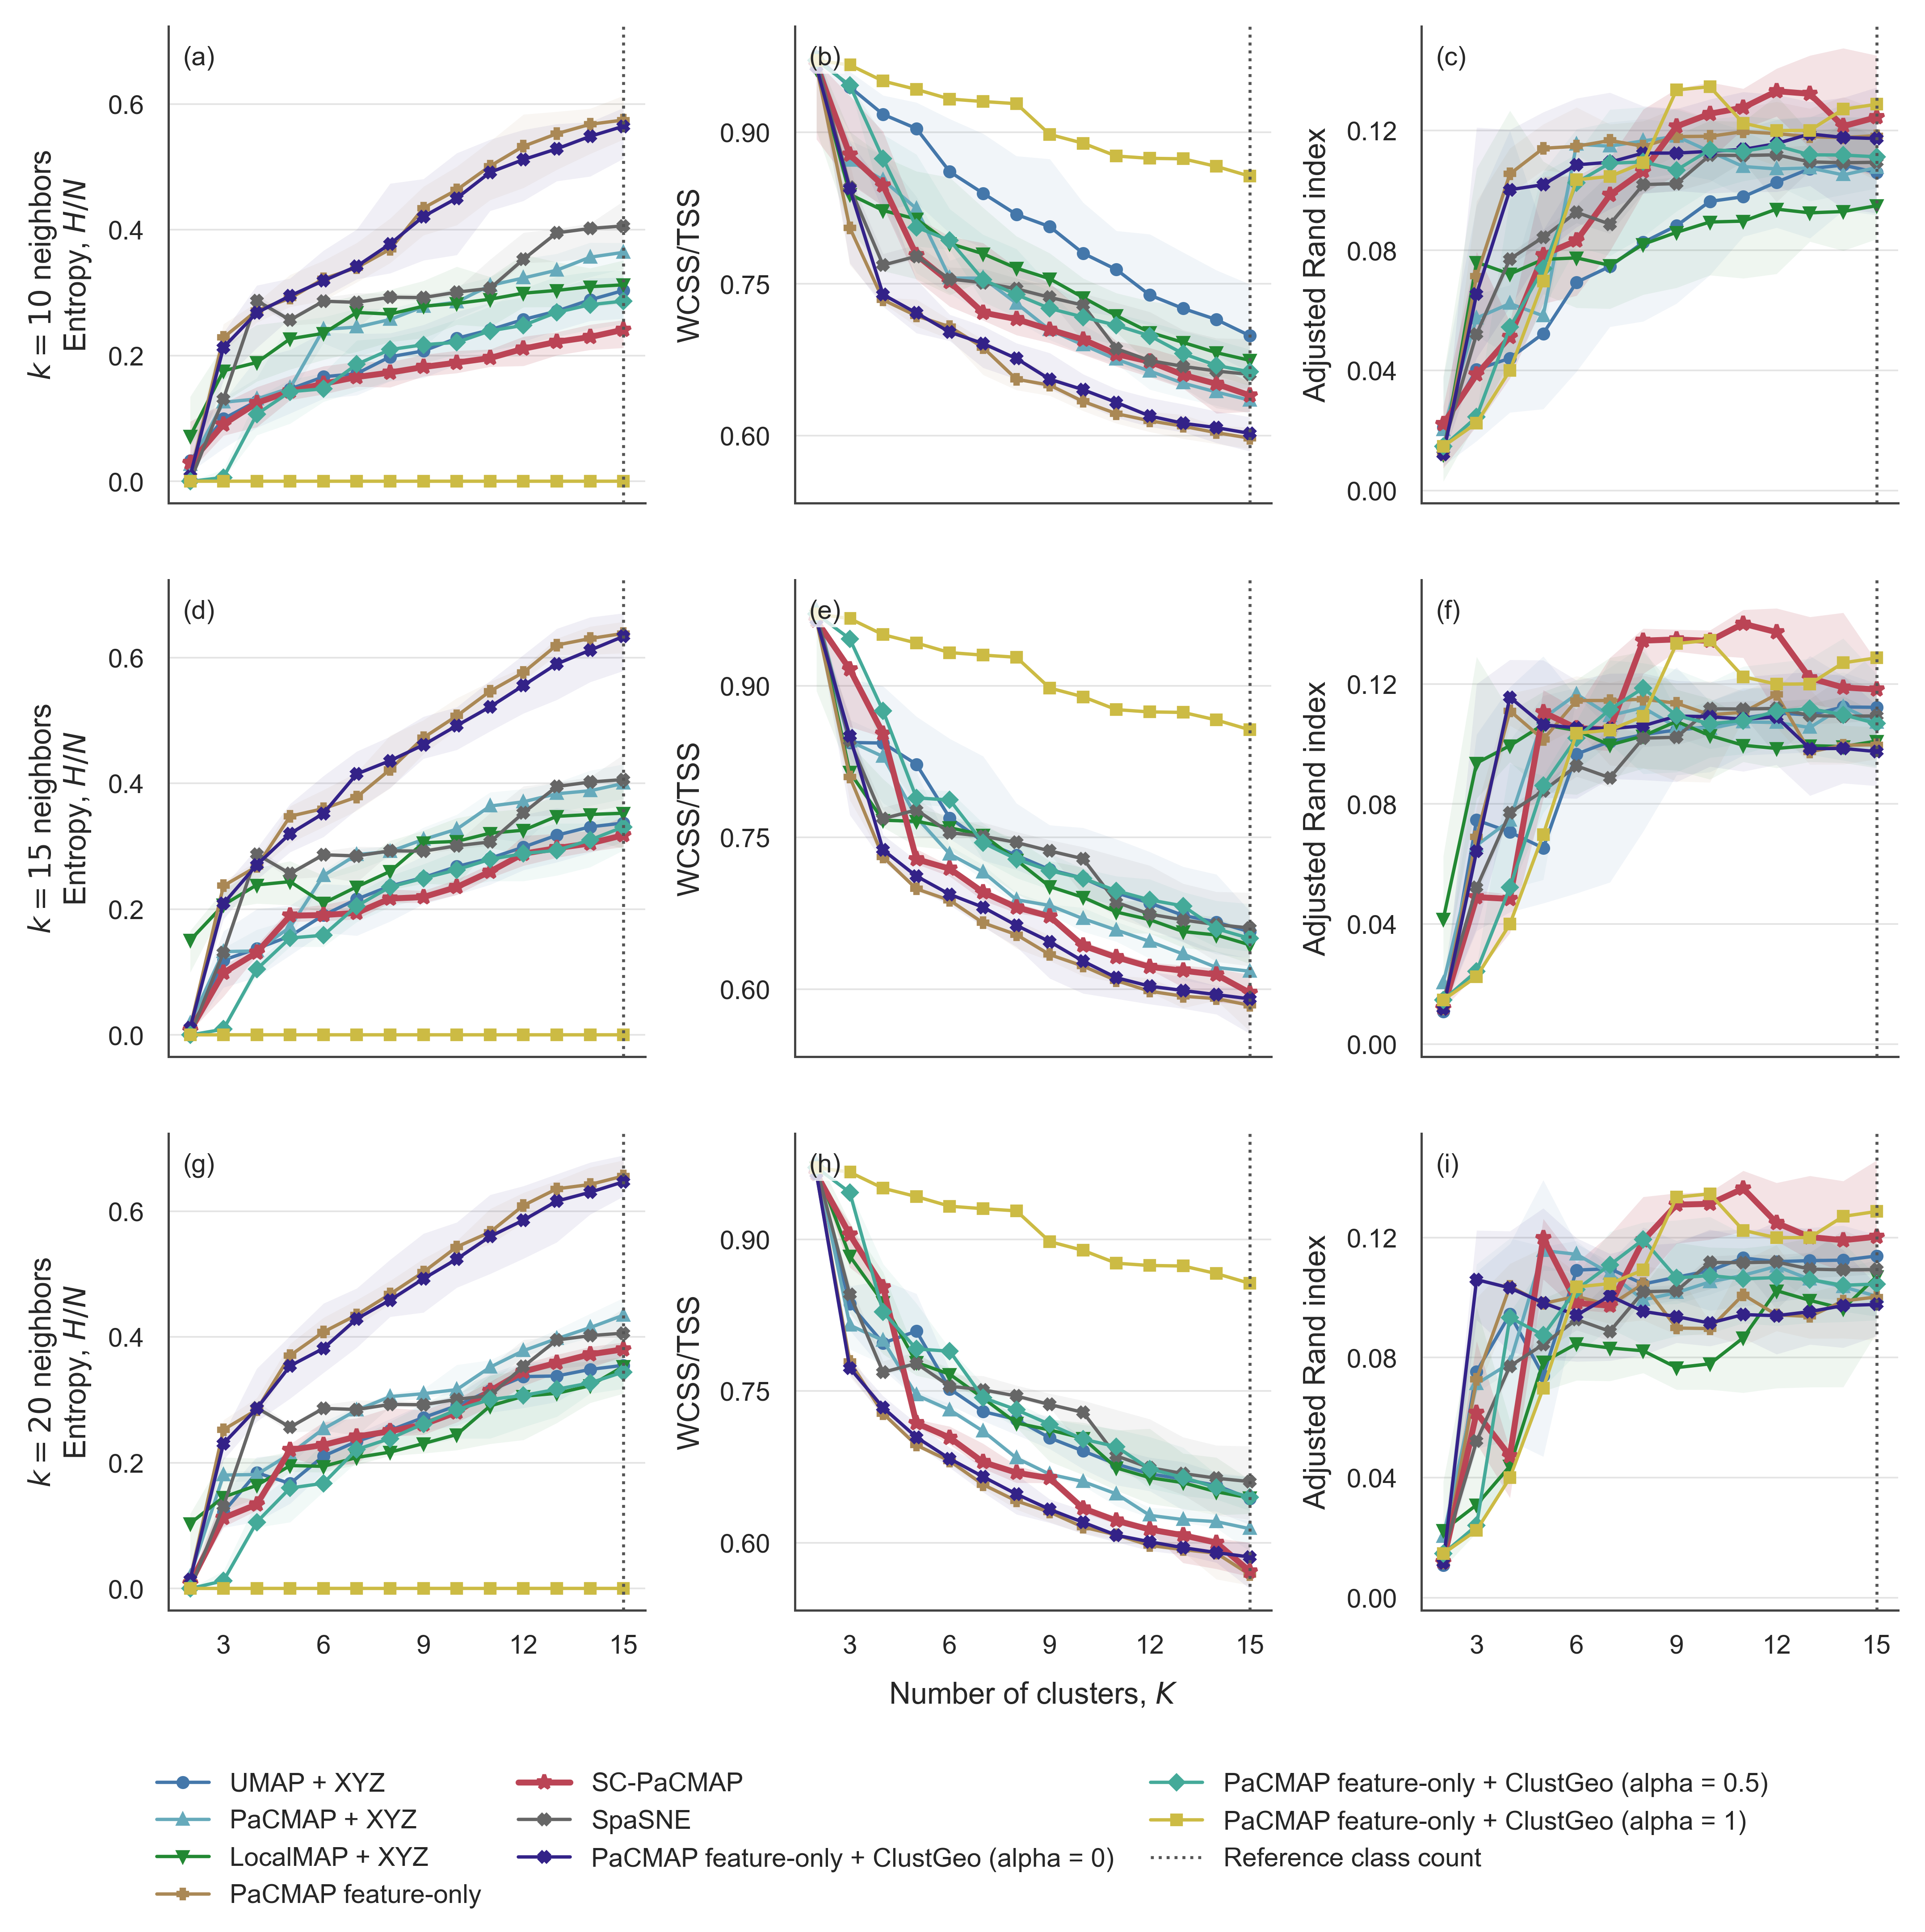

In [48]:

metric_specs = [('H_per_sample', r'Entropy, $H/N$'),
                ('WCSS_TSS', 'WCSS/TSS'), ('ARI', 'Adjusted Rand index')]
fig, axes = plt.subplots(len(NEIGHBOR_VALUES), 3, figsize=(7.1, 1.95 * len(NEIGHBOR_VALUES) + 1.35),
                         sharex=True, sharey='col', squeeze=False, layout='constrained')
for row, n_neighbors in enumerate(NEIGHBOR_VALUES):
    neighborhood_results = range_results[range_results.n_neighbors == n_neighbors]
    for col, (metric, metric_title) in enumerate(metric_specs):
        ax = axes[row, col]
        for method in METHODS:
            summary = neighborhood_results[neighborhood_results.method == method].groupby('K')[metric].agg(['median', 'min', 'max'])
            primary = method == 'SC-PaCMAP full graph'
            ax.fill_between(summary.index, summary['min'], summary['max'],
                            color=COLORS[method], alpha=.15 if primary else .07, linewidth=0)
            ax.plot(summary.index, summary['median'], color=COLORS[method], marker=MARKERS[method],
                    linewidth=1.6 if primary else .9, markersize=4 if primary else 2.5, label=METHOD_LABELS[method])
        ax.axvline(K_REFERENCE, color='#555555', ls=':', lw=.8)
        ax.set_box_aspect(1)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        ax.grid(axis='y')
        ax.set_ylabel(metric_title)
        if col == 0:
            ax.set_ylabel(f'$k={n_neighbors}$ neighbors\n{metric_title}')
        ax.text(.03, .96, f'({chr(97 + row * 3 + col)})', transform=ax.transAxes,
                va='top', fontsize=7, bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=1))
axes[-1, 1].set_xlabel('Number of clusters, $K$', labelpad=6)
handles, labels = axes[0, 0].get_legend_handles_labels()
handles.append(Line2D([], [], color='#555555', ls=':', lw=.8))
labels.append('Reference class count')
fig.legend(handles, labels, loc='outside lower center', ncol=3, columnspacing=1.4, handlelength=2)
paper_show(fig)


In [49]:
# Export this section as data for later paper figures.
save_section('evaluation_curves', tables={'seed_metrics': results})


Saved 1 data artifacts: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten\evaluation_curves


WindowsPath('C:/Users/weihong/Desktop/SC-PACMAP/sc-pacmap-reproducibility/results/notebook_exports/north_batten/evaluation_curves')

**Figure caption.** North Batten neighbourhood robustness. Panels (aâ€“c), (dâ€“f), and (gâ€“i) show fitting neighbourhoods $k=10,15,20$, respectively. Columns show entropy $H/N$, WCSS/TSS, and ARI. Lines are medians over 30 algorithm seeds (0â€“29); shading is the observed minimumâ€“maximum range. Dotted lines mark $K=15$. Geographic evaluation uses $k_e=10$. SpaSNE uses fixed perplexity 50 and its baseline is reused across rows.


## Three-metric results tables by map and neighbourhood size

Each row is one method and embedding neighbourhood **k** combination. The main
paper table fixes K-means cluster count **K** at the dataset's true class count.
All combinations are ranked by **mean spatial contiguity, highest first**.
Entries report **mean +/- sample standard deviation** across algorithm seeds.

All three scores are higher-is-better. Spatial contiguity (%) is
$100[1-(H/N)/\log(\min(K,k_e))]$; multivariate delineation (%) is
$100(1-\mathrm{WCSS}/\mathrm{TSS})$. ARI retains its original scale.
Scores are transformed for each seed before summarizing. The spatial evaluation
window remains fixed at 10 neighbours ($k_e=10$). SD describes seed variability on this
fixed dataset, not uncertainty across datasets.

SpaSNE uses fixed perplexity 50 and appears **once per K**, with embedding k
marked "?". Its repeated baseline is not counted as additional seeds.
Expand the full-sweep table for all cluster counts, ranked separately within each K.
Unrounded summaries are retained in `metric_summary`; formatted tables are
`reference_metric_table` and `sweep_metric_table`. The three-metric line charts
continue to show H/N, WCSS/TSS, and ARI with seed medians and min-max ranges.

In [50]:
from IPython.display import HTML, display

summary_keys = ['method', 'n_neighbors', 'K']
summary_input = results.loc[
    results.method.isin(METHODS) & results.n_neighbors.isin(NEIGHBOR_VALUES)
].copy()
# SpaSNE is reused across neighbour settings: count each seed only once per K.
summary_input = summary_input.loc[
    (summary_input.method != 'SpaSNE')
    | (summary_input.n_neighbors == NEIGHBOR_VALUES[0])
].copy()
assert not summary_input.duplicated(summary_keys + ['seed']).any()
assert (summary_input.K > 1).all(), 'Normalized spatial contiguity requires K > 1.'
summary_input['spatial_contiguity'] = 100 * (
    1 - summary_input.H_per_sample / np.log(np.minimum(summary_input.K, spatial_neighbors.shape[1]))
)
summary_input['multivariate_delineation'] = 100 * (1 - summary_input.WCSS_TSS)
summary_metrics = ['spatial_contiguity', 'multivariate_delineation', 'ARI']
summary_groups = summary_input.groupby(summary_keys, sort=False)
metric_summary = summary_groups[summary_metrics].agg(['mean', 'std'])
metric_summary.columns = [f'{metric}_{stat}' for metric, stat in metric_summary.columns]
metric_summary['n_seeds'] = summary_groups.seed.nunique()
metric_summary = metric_summary.reset_index()
# Keep the SC-PaCMAP diagnostics associated with each embedding neighbourhood.
# The geographic candidate graph is constructed with this same n_neighbors value.
sc_parameter_table = (
    results.loc[results.method == 'SC-PaCMAP full graph',
                ['n_neighbors', 'lambda_inferred', 'k_S']]
    .drop_duplicates()
    .sort_values('n_neighbors')
)
assert sc_parameter_table.n_neighbors.tolist() == list(NEIGHBOR_VALUES)
assert sc_parameter_table.groupby('n_neighbors').size().eq(1).all()
metric_summary = metric_summary.merge(sc_parameter_table, on='n_neighbors', how='left', validate='many_to_one')
metric_summary.loc[metric_summary.method != 'SC-PaCMAP full graph', ['lambda_inferred', 'k_S']] = np.nan
metric_summary = metric_summary.sort_values(
    ['K', 'spatial_contiguity_mean', 'method', 'n_neighbors'],
    ascending=[True, False, True, True],
).reset_index(drop=True)
metric_summary.loc[metric_summary.method == 'SpaSNE', 'n_neighbors'] = np.nan

sweep_metric_table = metric_summary[summary_keys + ['lambda_inferred', 'k_S', 'n_seeds']].copy()
sweep_metric_table['n_neighbors'] = [
    '\u2014' if pd.isna(value) else str(int(value))
    for value in sweep_metric_table.n_neighbors
]
sweep_metric_table['lambda_inferred'] = [
    'â€”' if pd.isna(value) else f'{value:.3f}'
    for value in sweep_metric_table.lambda_inferred
]
sweep_metric_table['k_S'] = [
    'â€”' if pd.isna(value) else str(int(value))
    for value in sweep_metric_table.k_S
]
for metric, title, digits in [
    ('spatial_contiguity', 'Spatial contiguity (%) \u2191', 2),
    ('multivariate_delineation', 'Multivariate delineation (%) \u2191', 2),
    ('ARI', 'ARI \u2191', 4),
]:
    sweep_metric_table[title] = [
        f'{mean:.{digits}f} \u00b1 {std:.{digits}f}'
        for mean, std in zip(metric_summary[f'{metric}_mean'], metric_summary[f'{metric}_std'])
    ]
sweep_metric_table = sweep_metric_table.rename(columns={
    'method': 'Method', 'n_neighbors': 'Neighbour k',
    'lambda_inferred': 'Inferred $\lambda_k$', 'k_S': '$k_{S,k}$', 'n_seeds': 'Seeds',
})
reference_metric_table = sweep_metric_table.loc[
    sweep_metric_table.K == K_REFERENCE
].drop(columns=['K']).reset_index(drop=True)
print(f'{DATASET_TITLE}: K={K_REFERENCE}; mean +/- sample SD across algorithm seeds')
display(HTML(reference_metric_table.to_html(index=False)))
display(HTML(
    '<details><summary>Full results table: all swept cluster counts K</summary>'
    + sweep_metric_table.to_html(index=False) + '</details>'
))


North Batten: K=15; mean +/- sample SD across algorithm seeds


Method,Neighbour k,Inferred $\lambda_k$,"$k_{S,k}$",Seeds,Spatial contiguity (%) ↑,Multivariate delineation (%) ↑,ARI ↑
PaCMAP feature-only + ClustGeo (alpha=1),10,â€”,â€”,30,100.00 ± 0.00,14.34 ± 0.00,0.1287 ± 0.0000
PaCMAP feature-only + ClustGeo (alpha=1),15,â€”,â€”,30,100.00 ± 0.00,14.34 ± 0.00,0.1287 ± 0.0000
PaCMAP feature-only + ClustGeo (alpha=1),20,â€”,â€”,30,100.00 ± 0.00,14.34 ± 0.00,0.1287 ± 0.0000
SC-PaCMAP full graph,10,0.511,5,30,89.70 ± 0.46,36.23 ± 0.86,0.1265 ± 0.0090
PaCMAP feature-only + ClustGeo (alpha=0.5),10,â€”,â€”,30,87.38 ± 0.96,33.54 ± 0.91,0.1133 ± 0.0048
UMAP + XYZ,10,â€”,â€”,30,86.97 ± 0.70,29.74 ± 2.07,0.1067 ± 0.0085
LocalMAP + XYZ,10,â€”,â€”,30,86.32 ± 0.72,32.66 ± 1.45,0.0960 ± 0.0080
SC-PaCMAP full graph,15,0.464,7,30,86.12 ± 0.62,40.08 ± 1.03,0.1175 ± 0.0047
PaCMAP feature-only + ClustGeo (alpha=0.5),15,â€”,â€”,30,85.76 ± 0.79,34.56 ± 1.21,0.1085 ± 0.0059
UMAP + XYZ,15,â€”,â€”,30,85.34 ± 0.56,34.39 ± 1.22,0.1125 ± 0.0067


Method,Neighbour k,K,Inferred $\lambda_k$,"$k_{S,k}$",Seeds,Spatial contiguity (%) ↑,Multivariate delineation (%) ↑,ARI ↑
PaCMAP feature-only + ClustGeo (alpha=0.5),10,2,â€”,â€”,30,100.00 ± 0.00,2.88 ± 0.00,0.0147 ± 0.0000
PaCMAP feature-only + ClustGeo (alpha=0.5),20,2,â€”,â€”,30,100.00 ± 0.00,2.88 ± 0.00,0.0147 ± 0.0000
PaCMAP feature-only + ClustGeo (alpha=1),10,2,â€”,â€”,30,100.00 ± 0.00,2.88 ± 0.00,0.0147 ± 0.0000
PaCMAP feature-only + ClustGeo (alpha=1),15,2,â€”,â€”,30,100.00 ± 0.00,2.88 ± 0.00,0.0147 ± 0.0000
PaCMAP feature-only + ClustGeo (alpha=1),20,2,â€”,â€”,30,100.00 ± 0.00,2.88 ± 0.00,0.0147 ± 0.0000
SpaSNE,—,2,â€”,â€”,30,100.00 ± 0.00,2.88 ± 0.00,0.0147 ± 0.0000
PaCMAP feature-only + ClustGeo (alpha=0.5),15,2,â€”,â€”,30,99.99 ± 0.06,2.89 ± 0.04,0.0147 ± 0.0001
UMAP + XYZ,20,2,â€”,â€”,30,99.55 ± 0.35,3.42 ± 0.17,0.0111 ± 0.0016
UMAP + XYZ,15,2,â€”,â€”,30,99.37 ± 0.71,3.39 ± 0.23,0.0114 ± 0.0021
SC-PaCMAP full graph,15,2,0.464,7,30,98.96 ± 0.13,3.53 ± 0.01,0.0121 ± 0.0002


In [51]:
# Export this section as data for later paper figures.
save_section('metric_tables', tables={'seed_metrics': summary_input,
             'numeric_summary': metric_summary, 'reference_table': reference_metric_table,
             'sweep_table': sweep_metric_table, 'sc_parameters': sc_parameter_table})


Saved 5 data artifacts: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten\metric_tables


WindowsPath('C:/Users/weihong/Desktop/SC-PACMAP/sc-pacmap-reproducibility/results/notebook_exports/north_batten/metric_tables')

### Statistical comparisons: SC-PaCMAP versus each baseline

At **K=K_REFERENCE**, compare the full-graph SC-PaCMAP with each active baseline
at the **same embedding neighbourhood size**, pairing runs by seed. SpaSNE's
single fixed-perplexity baseline is reused for each comparison, never pooled as
extra replicates. Use the seed-level scores above, not rounded table entries.
All three transformed metrics are higher-is-better; positive differences favour
SC-PaCMAP (percentage points for contiguity/delineation, original units for ARI).

We use **two-sided paired Wilcoxon signed-rank tests**, with **Holm family-wise
correction over all metrics, baselines and neighbourhood sizes in this notebook**
at alpha=0.05. Two-sided tests allow either method to win without choosing the
alternative after seeing results. This is an exploratory analysis of existing
results, not a preregistered confirmatory test. No tests are selected from the K
sweep. For a single paper-wide family spanning all three notebooks, combine their
raw p-values and apply Holm again; these adjustments are dataset-specific.

The signed-rank model assumes independent seed pairs and approximately symmetric
paired differences. Matching seed numbers defines the run blocks; it does not
imply identical random draws across algorithms. Inspect the differences retained
in `metric_paired_differences` for this assumption. If symmetry is implausible,
prespecify a paired sign test instead. Differences are rounded to 12 decimal
places only for ranking/zero detection. Zeros are discarded from signed ranks;
all-zero comparisons receive p=1. With ties, use reproducible sign permutations
(99,999 resamples, or exhaustive when feasible); otherwise use exact Wilcoxon.

`metric_stat_tests` retains raw and adjusted p-values, sample sizes, mean/median
paired improvements, wins/ties/losses, and matched-pairs rank-biserial effects
(-1 to +1; positive favours SC-PaCMAP). The bootstrap 95% interval for the mean
improvement resamples seed pairs (10,000 draws); it is **pointwise**, not adjusted
for multiplicity, and is not the signed-rank test's confidence interval.

**Scope for the paper:** these are algorithm-randomness comparisons conditional
on this fixed dataset and clustering configuration. Thirty seeds are not thirty
independent datasets; spatial samples, K values and neighbourhoods are not extra
replicates. A significant result for one metric does not imply overall superiority.
Broader generalization requires independent datasets or an appropriately designed
spatial/group resampling study. Friedman with post-hoc comparisons is relevant
for multiple methods across independent datasets; three datasets offer limited power.

References: [SciPy Wilcoxon documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html),
[Holm correction](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html),
[DemÅ¡ar (2006)](https://jmlr.org/papers/v7/demsar06a.html).


In [52]:
from scipy.stats import PermutationMethod, rankdata, wilcoxon

STAT_ALPHA = 0.05
STAT_RESAMPLES = 99_999
STAT_BOOTSTRAPS = 10_000
STAT_RANDOM_SEED = 2026
STAT_PRIMARY = 'SC-PaCMAP full graph'

def metric_holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    adjusted[order] = np.minimum(1., np.maximum.accumulate(
        p_values[order] * np.arange(len(p_values), 0, -1)
    ))
    return adjusted

def compare_metric_seeds(frame):
    expected_seeds = pd.Index(SEEDS, name='seed')
    if len(expected_seeds) < 2 or not expected_seeds.is_unique:
        raise ValueError('Use at least two distinct algorithm seeds.')
    if STAT_PRIMARY not in METHODS or len(METHODS) < 2:
        raise ValueError('SC-PaCMAP and at least one baseline must be active.')
    records, paired_records = [], []
    boot_rng = np.random.default_rng(STAT_RANDOM_SEED)

    def seed_scores(method, neighbors):
        selected = frame.loc[
            (frame.K == K_REFERENCE) & (frame.method == method)
            & (frame.n_neighbors == neighbors), ['seed'] + summary_metrics
        ]
        if selected.seed.duplicated().any() or set(selected.seed) != set(SEEDS):
            raise ValueError(f'{method}, n={neighbors}: missing/extra/duplicate seeds; rerun evaluation.')
        selected = selected.set_index('seed').reindex(expected_seeds)
        if not np.isfinite(selected.to_numpy(dtype=float)).all():
            raise ValueError(f'{method}, n={neighbors}: non-finite scores.')
        return selected

    for neighbors in NEIGHBOR_VALUES:
        primary = seed_scores(STAT_PRIMARY, neighbors)
        for baseline in [m for m in METHODS if m != STAT_PRIMARY]:
            baseline_neighbors = NEIGHBOR_VALUES[0] if baseline == 'SpaSNE' else neighbors
            other = seed_scores(baseline, baseline_neighbors)
            for metric in summary_metrics:
                raw_d = (primary[metric] - other[metric]).to_numpy(dtype=float)
                d = np.round(raw_d, 12)
                nonzero = d[d != 0]
                if len(nonzero) == 0:
                    statistic, p_value, effect, engine = 0., 1., 0., 'all tied'
                else:
                    ranks = rankdata(np.abs(nonzero), method='average')
                    effect = float(np.sum(np.sign(nonzero) * ranks) / np.sum(ranks))
                    tied_ranks = len(np.unique(np.abs(nonzero))) < len(nonzero)
                    engine = 'permutation' if tied_ranks else 'exact'
                    test_method = (PermutationMethod(
                        n_resamples=STAT_RESAMPLES, batch=2048,
                        random_state=STAT_RANDOM_SEED,
                    ) if tied_ranks else 'exact')
                    test = wilcoxon(nonzero, alternative='two-sided',
                                    zero_method='wilcox', method=test_method)
                    statistic, p_value = float(test.statistic), float(test.pvalue)
                bootstrap_means = raw_d[boot_rng.integers(
                    0, len(raw_d), size=(STAT_BOOTSTRAPS, len(raw_d))
                )].mean(axis=1)
                ci_low, ci_high = np.quantile(bootstrap_means, [.025, .975])
                records.append({
                    'dataset': DATASET_TITLE, 'K': K_REFERENCE,
                    'n_neighbors': neighbors, 'baseline': baseline, 'metric': metric,
                    'n_pairs': len(d), 'n_nonzero': len(nonzero),
                    'mean_delta': raw_d.mean(), 'median_delta': np.median(raw_d),
                    'mean_ci95_low': ci_low, 'mean_ci95_high': ci_high,
                    'rank_biserial': effect, 'wins': int((d > 0).sum()),
                    'ties': int((d == 0).sum()), 'losses': int((d < 0).sum()),
                    'W': statistic, 'p_raw': p_value, 'p_engine': engine,
                })
                paired_records.extend({
                    'n_neighbors': neighbors, 'baseline': baseline, 'metric': metric,
                    'seed': seed, 'delta': delta,
                } for seed, delta in zip(expected_seeds, raw_d))
    table = pd.DataFrame(records)
    table['p_holm'] = metric_holm_adjust(table.p_raw)
    table['conclusion'] = [
        ('SC-PaCMAP higher' if effect > 0 else 'Baseline higher')
        if p < STAT_ALPHA and effect != 0 else 'No significant difference'
        for p, effect in zip(table.p_holm, table.rank_biserial)
    ]
    return table, pd.DataFrame(paired_records)

# summary_input contains unrounded per-seed transformed metrics from the cell above.
metric_stat_tests, metric_paired_differences = compare_metric_seeds(summary_input)
print(f'{DATASET_TITLE}: K={K_REFERENCE}; two-sided paired Wilcoxon; '
      f'Holm across {len(metric_stat_tests)} comparisons, alpha={STAT_ALPHA}')
print('Positive delta/effect favours SC-PaCMAP. Inference is across seeds on this fixed dataset.')
for metric in summary_metrics:
    print(metric)
    display(metric_stat_tests.loc[metric_stat_tests.metric == metric, [
        'n_neighbors', 'baseline', 'n_pairs', 'n_nonzero', 'mean_delta',
        'median_delta', 'mean_ci95_low', 'mean_ci95_high', 'rank_biserial',
        'wins', 'ties', 'losses', 'p_raw', 'p_holm', 'conclusion',
    ]].style.format({
        **{c: '{:.4f}' for c in ['mean_delta', 'median_delta', 'mean_ci95_low',
                                'mean_ci95_high', 'rank_biserial']},
        'p_raw': '{:.3g}', 'p_holm': '{:.3g}',
    }))


North Batten: K=15; two-sided paired Wilcoxon; Holm across 72 comparisons, alpha=0.05
Positive delta/effect favours SC-PaCMAP. Inference is across seeds on this fixed dataset.
spatial_contiguity


,n_neighbors,baseline,n_pairs,n_nonzero,mean_delta,median_delta,mean_ci95_low,mean_ci95_high,rank_biserial,wins,ties,losses,p_raw,p_holm,conclusion
0,10,UMAP + XYZ,30,30,2.7291,2.8039,2.3894,3.0594,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
3,10,PaCMAP + XYZ,30,30,5.4466,5.5420,5.2115,5.6777,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
6,10,LocalMAP + XYZ,30,30,3.3756,3.3739,3.0839,3.6688,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
9,10,PaCMAP feature-only,30,30,14.6054,14.4505,14.2768,14.9404,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
12,10,SpaSNE,30,30,7.3671,7.3088,7.1200,7.5972,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
15,10,PaCMAP feature-only + ClustGeo (alpha=0),30,30,13.9537,14.1349,13.5990,14.2974,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
18,10,PaCMAP feature-only + ClustGeo (alpha=0.5),30,30,2.3206,2.1987,1.9938,2.6714,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
21,10,PaCMAP feature-only + ClustGeo (alpha=1),30,30,-10.3017,-10.4725,-10.4629,-10.1354,-1.0000,0,0,30,1.86e-09,1.34e-07,Baseline higher
24,15,UMAP + XYZ,30,30,0.7786,0.7278,0.4697,1.0785,0.8022,24,0,6,3.45e-05,0.000345,SC-PaCMAP higher
27,15,PaCMAP + XYZ,30,30,3.5430,3.6580,3.2311,3.8440,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher


multivariate_delineation


,n_neighbors,baseline,n_pairs,n_nonzero,mean_delta,median_delta,mean_ci95_low,mean_ci95_high,rank_biserial,wins,ties,losses,p_raw,p_holm,conclusion
1,10,UMAP + XYZ,30,30,6.4957,6.3115,5.7138,7.2963,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
4,10,PaCMAP + XYZ,30,30,-0.2833,-0.4609,-0.7301,0.1658,-0.2559,13,0,17,0.229,0.594,No significant difference
7,10,LocalMAP + XYZ,30,30,3.5704,3.4284,3.0427,4.1076,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
10,10,PaCMAP feature-only,30,30,-4.0456,-3.9471,-4.4281,-3.6626,-1.0000,0,0,30,1.86e-09,1.34e-07,Baseline higher
13,10,SpaSNE,30,30,2.2297,2.3554,1.6629,2.7626,0.9226,28,0,2,4.71e-07,7.07e-06,SC-PaCMAP higher
16,10,PaCMAP feature-only + ClustGeo (alpha=0),30,30,-3.4992,-3.2774,-3.9256,-3.1019,-1.0000,0,0,30,1.86e-09,1.34e-07,Baseline higher
19,10,PaCMAP feature-only + ClustGeo (alpha=0.5),30,30,2.6902,2.5803,2.2699,3.1196,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
22,10,PaCMAP feature-only + ClustGeo (alpha=1),30,30,21.8936,21.6987,21.5935,22.1877,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
25,15,UMAP + XYZ,30,30,5.6834,5.8540,5.1473,6.2177,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
28,15,PaCMAP + XYZ,30,30,1.6523,1.4170,1.2063,2.1050,0.9355,27,0,3,2.55e-07,4.34e-06,SC-PaCMAP higher


ARI


,n_neighbors,baseline,n_pairs,n_nonzero,mean_delta,median_delta,mean_ci95_low,mean_ci95_high,rank_biserial,wins,ties,losses,p_raw,p_holm,conclusion
2,10,UMAP + XYZ,30,30,0.0198,0.0188,0.0151,0.0244,0.9613,29,0,1,6.15e-08,1.23e-06,SC-PaCMAP higher
5,10,PaCMAP + XYZ,30,30,0.0183,0.0175,0.0145,0.0222,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
8,10,LocalMAP + XYZ,30,30,0.0305,0.0327,0.0268,0.0340,1.0000,30,0,0,1.86e-09,1.34e-07,SC-PaCMAP higher
11,10,PaCMAP feature-only,30,30,0.0096,0.0083,0.0060,0.0133,0.8323,26,0,4,1.4e-05,0.000154,SC-PaCMAP higher
14,10,SpaSNE,30,30,0.0166,0.0154,0.0132,0.0199,0.9699,27,0,3,3.54e-08,7.79e-07,SC-PaCMAP higher
17,10,PaCMAP feature-only + ClustGeo (alpha=0),30,30,0.0108,0.0127,0.0066,0.0149,0.7892,25,0,5,4.97e-05,0.000447,SC-PaCMAP higher
20,10,PaCMAP feature-only + ClustGeo (alpha=0.5),30,30,0.0132,0.0126,0.0096,0.0167,0.9183,28,0,2,5.72e-07,8.01e-06,SC-PaCMAP higher
23,10,PaCMAP feature-only + ClustGeo (alpha=1),30,30,-0.0022,-0.0043,-0.0053,0.0010,-0.2731,11,0,19,0.198,0.594,No significant difference
26,15,UMAP + XYZ,30,30,0.0050,0.0062,0.0022,0.0076,0.6387,23,0,7,0.00158,0.0095,SC-PaCMAP higher
29,15,PaCMAP + XYZ,30,30,0.0094,0.0102,0.0064,0.0123,0.8839,28,0,2,2.35e-06,2.82e-05,SC-PaCMAP higher


In [53]:
# Export this section as data for later paper figures.
save_section('statistical_comparisons', tables={'tests': metric_stat_tests,
             'paired_differences': metric_paired_differences})


Saved 2 data artifacts: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten\statistical_comparisons


WindowsPath('C:/Users/weihong/Desktop/SC-PACMAP/sc-pacmap-reproducibility/results/notebook_exports/north_batten/statistical_comparisons')

## Combined spatialâ€“multivariate performance plane at the true class count

One plot combines all seed results at **K=K_REFERENCE**. **Color identifies the method; shape identifies embedding neighborhood size:** circles for 10, triangles for 15, and squares for 20. Each neighborhood-dependent method contributes **90 small transparent points** (30 paired seeds ? three settings). SpaSNE contributes **30 diamond points**, shown once because its fixed-perplexity results are reused across neighborhood settings.

Large outlined markers show the median for each method?neighborhood combination; set `SHOW_CLOUD_MEDIANS=False` to display only the seed points. The geographic evaluation window stays fixed at 10 neighbors ($k_e=10$). The axes use the same higher-is-better scores as the tables: spatial contiguity (%) = $100[1 - (H/N)/\log(\min(K,k_e))]$ and multivariate delineation (%) = $100(1 - WCSS/TSS)$. Scores are transformed per seed before computing medians. Upper-right is better jointly; these points show paired algorithm runs, not independent datasets.

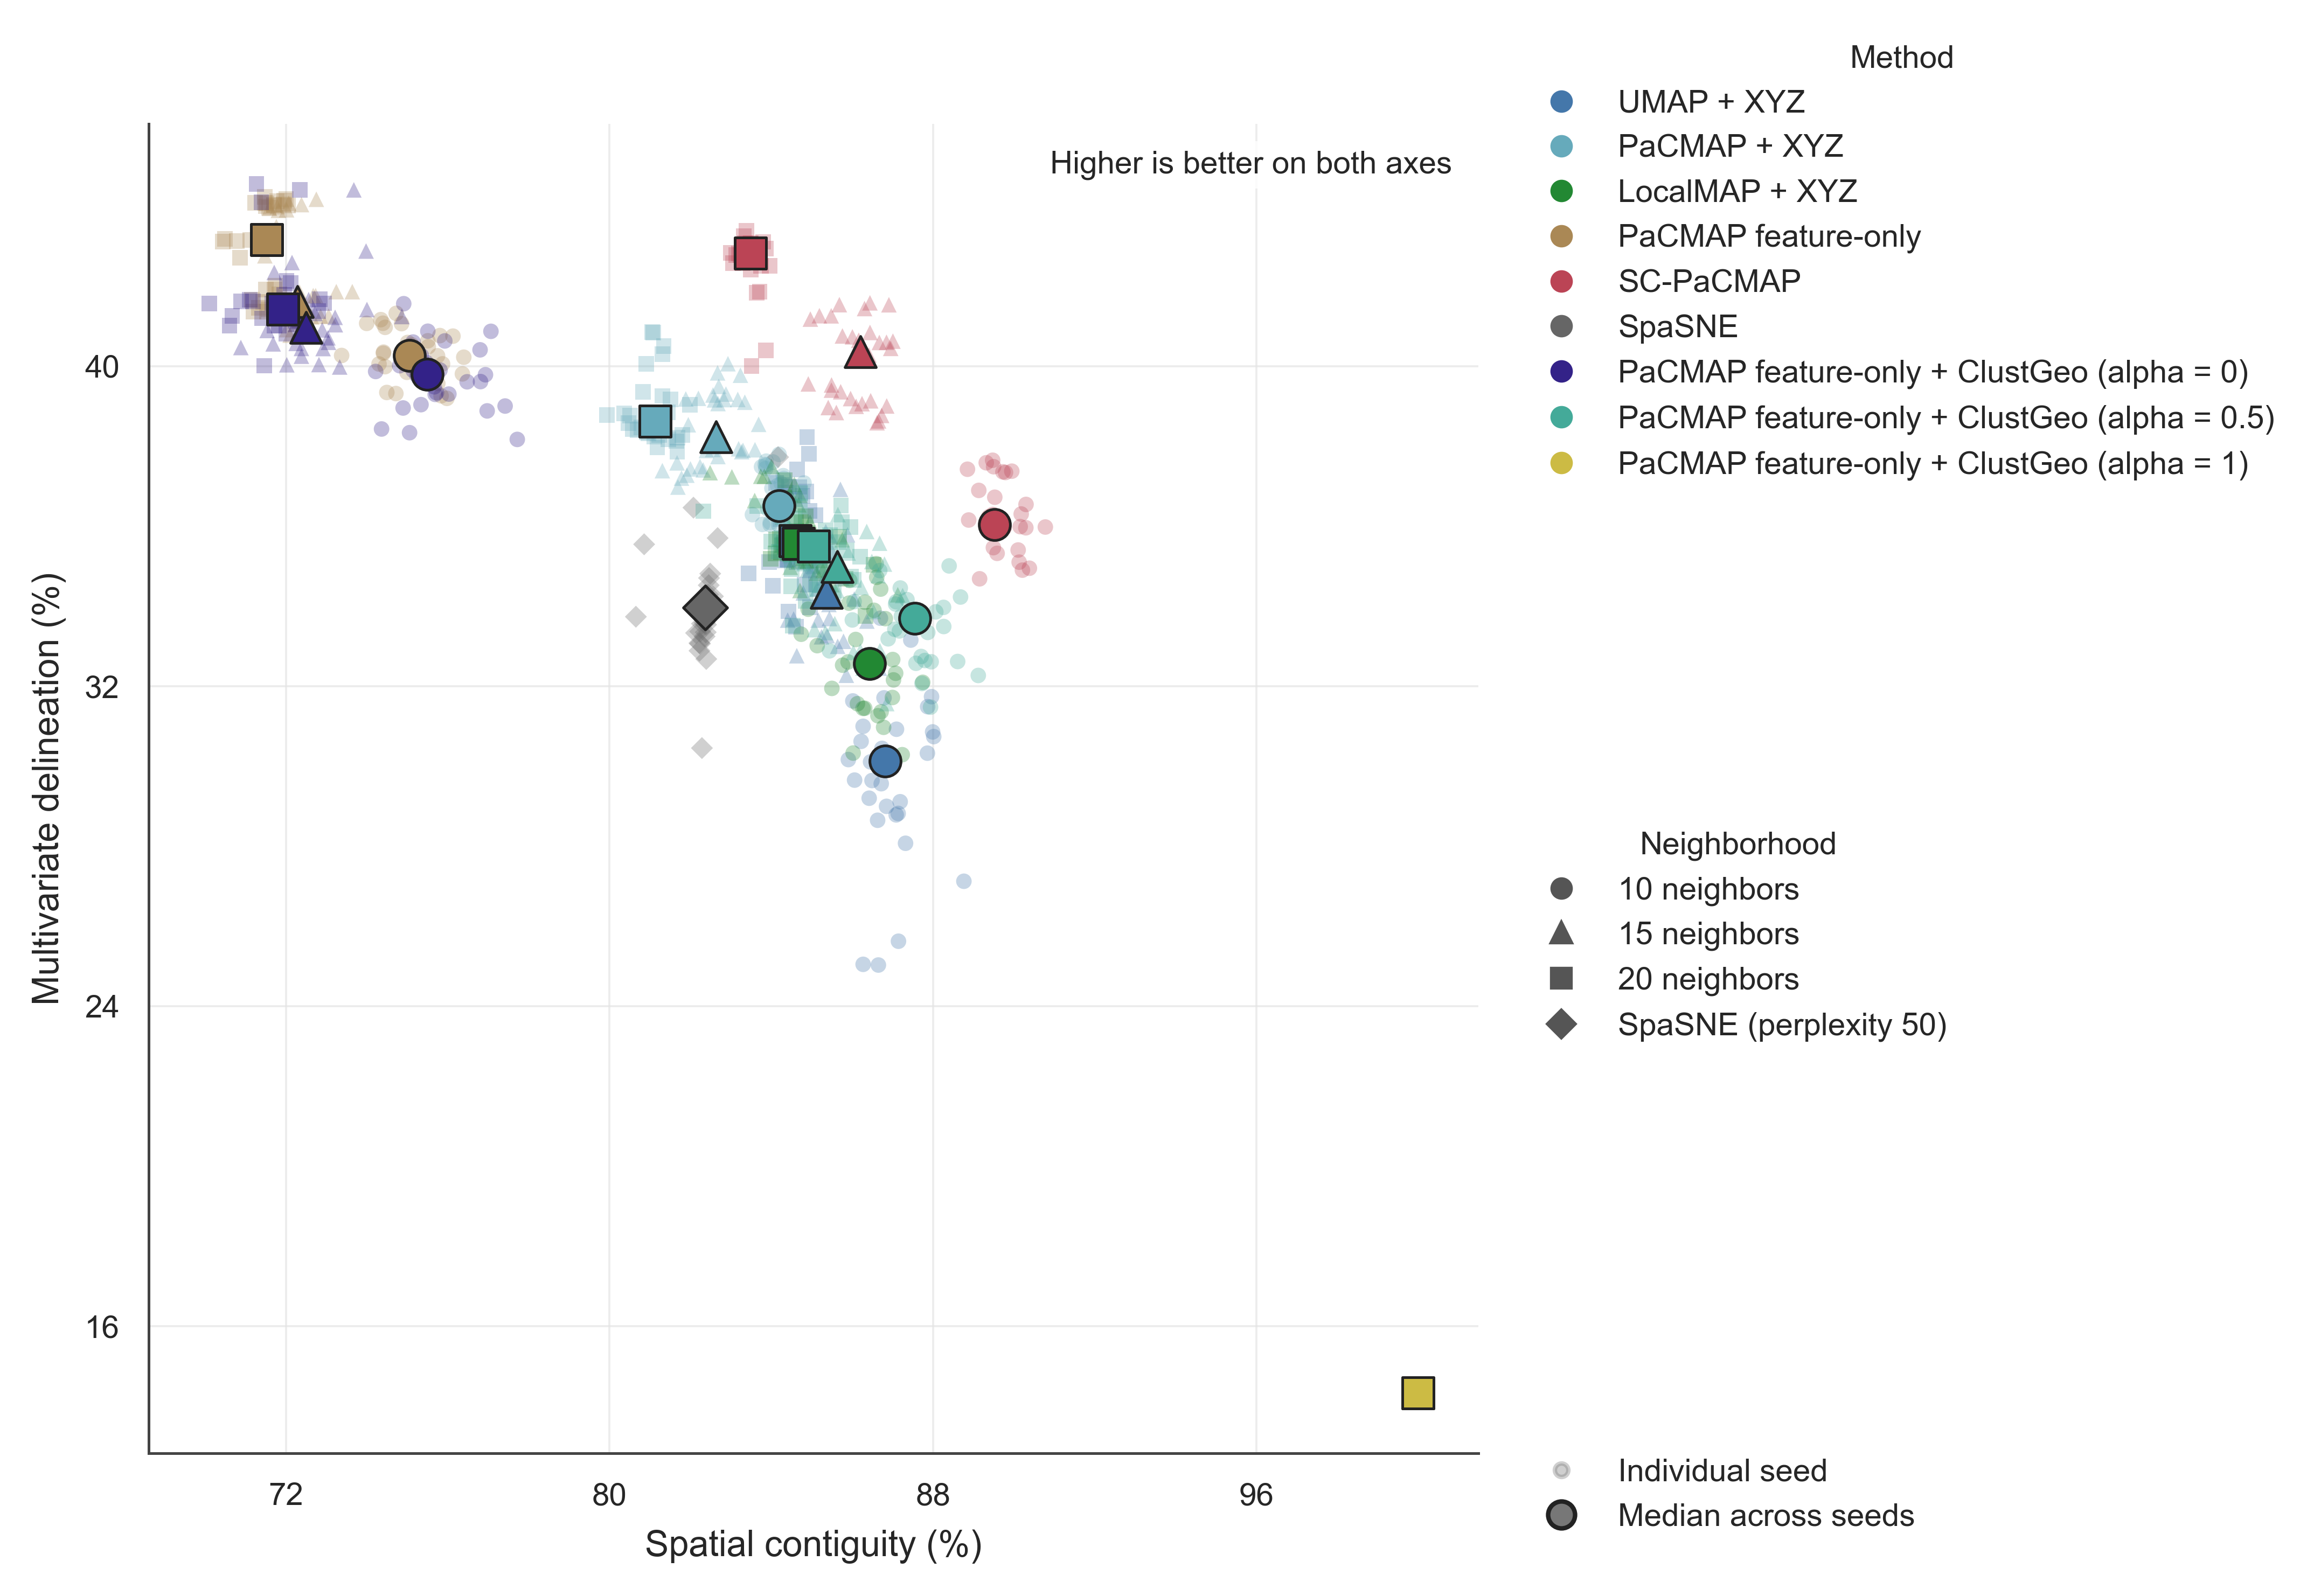

In [54]:

from matplotlib.lines import Line2D
cloud = results[(results.K == K_REFERENCE) & results.method.isin(METHODS) & results.n_neighbors.isin(NEIGHBOR_VALUES)].copy()
# SpaSNE's fixed-perplexity run is shown once per seed.
cloud = cloud[(cloud.method != 'SpaSNE') | (cloud.n_neighbors == NEIGHBOR_VALUES[0])]
# Match the higher-is-better scores in the metric tables.
assert (cloud.K > 1).all(), 'Normalized spatial contiguity requires K > 1.'
cloud['spatial_contiguity'] = 100 * (1 - cloud.H_per_sample / np.log(np.minimum(cloud.K, spatial_neighbors.shape[1])))
cloud['multivariate_delineation'] = 100 * (1 - cloud.WCSS_TSS)
cloud_medians = cloud.groupby(['n_neighbors', 'method'])[['spatial_contiguity', 'multivariate_delineation']].median()
NEIGHBOR_MARKERS = {10: 'o', 15: '^', 20: 's'}
SHOW_CLOUD_MEDIANS = True
fig = plt.figure(figsize=(7.1, 4.8), layout='constrained')
grid = fig.add_gridspec(1, 2, width_ratios=[1, .58])
ax = fig.add_subplot(grid[0, 0])
legend_ax = fig.add_subplot(grid[0, 1])
legend_ax.set_axis_off()
for method in METHODS:
    neighbor_settings = (NEIGHBOR_VALUES[0],) if method == 'SpaSNE' else NEIGHBOR_VALUES
    for n_neighbors in neighbor_settings:
        part = cloud[(cloud.method == method) & (cloud.n_neighbors == n_neighbors)]
        marker = 'D' if method == 'SpaSNE' else NEIGHBOR_MARKERS[n_neighbors]
        ax.scatter(part.spatial_contiguity, part.multivariate_delineation, color=COLORS[method],
                   marker=marker, s=12, alpha=.3, edgecolors='none')
        if SHOW_CLOUD_MEDIANS:
            median = cloud_medians.loc[(n_neighbors, method)]
            ax.scatter(median.spatial_contiguity, median.multivariate_delineation, color=COLORS[method],
                       marker=marker, s=48, edgecolor='#222222', linewidth=.6, zorder=4)
ax.set(xlabel='Spatial contiguity (%)', ylabel='Multivariate delineation (%)')
ax.text(.98, .98, 'Higher is better on both axes', transform=ax.transAxes,
        ha='right', va='top', fontsize=7,
        bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=2))
ax.set_box_aspect(1)
ax.grid(alpha=.7)
ax.xaxis.set_major_locator(MaxNLocator(5))
ax.yaxis.set_major_locator(MaxNLocator(5))
method_handles = [Line2D([], [], color=COLORS[m], marker='o', linestyle='None', markersize=4, label=METHOD_LABELS[m]) for m in METHODS]
method_legend = legend_ax.legend(handles=method_handles, title='Method', loc='upper left',
                                  bbox_to_anchor=(0, 1), borderaxespad=0)
legend_ax.add_artist(method_legend)
neighbor_handles = [Line2D([], [], color='#555555', marker=NEIGHBOR_MARKERS[n], linestyle='None',
                           markersize=4, label=f'{n} neighbors') for n in NEIGHBOR_VALUES]
neighbor_handles.append(Line2D([], [], color='#555555', marker='D', linestyle='None',
                               markersize=4, label='SpaSNE (perplexity 50)'))
neighbor_legend = legend_ax.legend(handles=neighbor_handles, title='Neighborhood', loc='upper left',
                                    bbox_to_anchor=(0, .48), borderaxespad=0)
legend_ax.add_artist(neighbor_legend)
point_handles = [Line2D([], [], color='#777777', marker='o', linestyle='None', alpha=.35, markersize=3, label='Individual seed')]
if SHOW_CLOUD_MEDIANS:
    point_handles.append(Line2D([], [], color='#777777', marker='o', markeredgecolor='#222222',
                                linestyle='None', markersize=6, label='Median across seeds'))
legend_ax.legend(handles=point_handles, loc='lower left', bbox_to_anchor=(0, 0), borderaxespad=0)
paper_show(fig)


In [55]:
# Export this section as data for later paper figures.
save_section('performance_plane', tables={'seed_points': cloud,
             'medians': cloud_medians.reset_index()})


Saved 2 data artifacts: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten\performance_plane


WindowsPath('C:/Users/weihong/Desktop/SC-PACMAP/sc-pacmap-reproducibility/results/notebook_exports/north_batten/performance_plane')

**Figure caption.** North Batten spatialâ€“multivariate performance at $K=15$. Colour identifies method; circles, triangles, and squares identify fitting neighbourhoods $k=10,15,20$. Small translucent points show 30 seeds per setting; large outlined markers show medians (when `SHOW_CLOUD_MEDIANS=True`). SpaSNE uses diamonds and contributes 30 seeds once at fixed perplexity 50. Evaluation uses $k_e=10$. Both axes are higher-is-better percentages.


## Hole confounding: graph composition and cross-group continuity

**Methodology.** For each directed graph, the within-hole fraction is the number of edges whose endpoints share `group_id`, divided by the total number of edges. CMiO uses individual deposit names, not deposit-type labels; North Batten uses drillhole IDs. We report the ordinary geochemical feature-neighbour graph ($G_F$), the geographic candidate graph ($G_G$), and the selected spatial constraint graph ($G_S$) separately. Fractions are unweighted edge counts, including spatial edges overlapping the feature-neighbour graph, at the reference setting (seed 0, 10 neighbours); an empty graph has an undefined fraction.

To assess whether spatial continuity extends beyond within-hole smoothing, we select each sample's 10 nearest spatial neighbours **after excluding all samples from its own hole**. Across 30 algorithm seeds (0?29), we report continuity as $100[1-\overline{H}/\log(\min(K,k_e))]$, where $H$ is the entropy of cluster memberships among the eligible neighbours, $K$ is the reference cluster count, and $k_e=10$ is the number of eligible cross-group neighbours per sample. Higher values mean more homogeneous neighbouring cluster memberships. The focal sample is excluded. These are diagnostics on full-data fitted embeddings, not held-out-group predictions; homogeneous neighbours need not share the focal sample's cluster. Paired seed differences and Holm-adjusted Wilcoxon tests compare SC-PaCMAP with the baselines; seed ranges describe algorithm variability, not independent geological replication.

ARI provides supporting agreement with evaluation labels only and is not evidence of multivariate delineation. Interpret cross-group continuity alongside geochemical WCSS/TSS. A gain beyond local smoothing must be supported by the cross-group results rather than inferred from the within-group fractions alone.

In [ ]:
from IPython.display import display
from sc_pacmap import original as graph_backend

group_values = data['group_id'].to_numpy()
assert not pd.isna(group_values).any(), 'Group IDs are required for every sample.'
_, geographic_candidates, _ = graph_backend.compute_nearest_neighbors(
    np.ascontiguousarray(coords, dtype=np.float32), N_NEIGHBORS,
    'euclidean', settings_base['knn_backend'], 0,
)
graph_rows = []
for graph_name, neighbors in [
    ('G_F: feature neighbours', one_seed_diag.ordinary_neighbors),
    ('G_S: selected spatial constraints', one_seed_diag.selected_spatial_neighbors),
    ('Geographic candidates', geographic_candidates),
]:
    neighbors = np.asarray(neighbors, dtype=int)
    same = group_values[:, None] == group_values[neighbors]
    graph_rows.append({
        'graph': graph_name, 'directed_edges': int(same.size),
        'within_group_edges': int(same.sum()),
        'cross_group_edges': int(same.size - same.sum()),
        'within_group_fraction': float(same.mean()) if same.size else np.nan,
    })
graph_confounding = pd.DataFrame(graph_rows)
display(graph_confounding.round(4))

In [ ]:
# Export this section as data for later paper figures.
save_section('graph_composition', tables={'edge_fractions': graph_confounding})


### Cross-hole continuity results

The following stored results use the exclusion and entropy definition above. Run this section to refresh the 30-seed comparison.


In [58]:
from scipy.stats import wilcoxon


def paired_wilcoxon_table(frame, value_column, primary_method='SC-PaCMAP full graph'):
    rows = []
    comparator_methods = [method for method in METHODS if method != primary_method]
    for comparator in comparator_methods:
        paired = frame.pivot(index='seed', columns='method', values=value_column).dropna()
        differences = paired[primary_method] - paired[comparator]
        if np.allclose(differences, 0.0):
            statistic, p_value = 0.0, 1.0
        else:
            test = wilcoxon(
                differences,
                alternative='greater',
                zero_method='wilcox',
                method='auto',
            )
            statistic, p_value = float(test.statistic), float(test.pvalue)
        rows.append({
            'primary': primary_method,
            'comparator': comparator,
            'paired_seeds': len(differences),
            'median_difference': float(np.median(differences)),
            'primary_wins': int(np.sum(differences > 0)),
            'ties': int(np.sum(differences == 0)),
            'wilcoxon_statistic': statistic,
            'p_greater': p_value,
        })
    results = pd.DataFrame(rows).sort_values('p_greater').reset_index(drop=True)
    running_maximum = 0.0
    adjusted = []
    for rank, p_value in enumerate(results['p_greater']):
        corrected = min(1.0, p_value * (len(results) - rank))
        running_maximum = max(running_maximum, corrected)
        adjusted.append(running_maximum)
    results['holm_p'] = adjusted
    return results


def cross_hole_neighbors(coordinates, holes, n=N_NEIGHBORS):
    distances = ((coordinates[:, None, :] - coordinates[None, :, :]) ** 2).sum(2)
    distances[holes[:, None] == holes[None, :]] = np.inf
    np.fill_diagonal(distances, np.inf)
    if np.any(np.isfinite(distances).sum(axis=1) < n):
        raise ValueError('Fewer than n eligible cross-group neighbours for at least one sample.')
    return np.argsort(distances, axis=1)[:, :n]

cross_neighbors = cross_hole_neighbors(coords, data.group_id.astype(str).to_numpy())
holdout_rows = []
for seed in CROSS_GROUP_SEEDS:
    for method in METHODS:
        labels = benchmark_clusters[(seed, N_NEIGHBORS, method, K_REFERENCE)]
        holdout_rows.append({
            'seed': seed,
            'method': method,
            'cross_hole_spatial': 100 * (
                1 - entropy(labels, cross_neighbors) / np.log(min(K_REFERENCE, cross_neighbors.shape[1]))
            ),
        })

holdout = pd.DataFrame(holdout_rows)
display(
    holdout.groupby('method').cross_hole_spatial
    .agg(['median', 'min', 'max'])
    .round(2)
)



cross_hole_tests = paired_wilcoxon_table(holdout, 'cross_hole_spatial')
display(cross_hole_tests.round(4))
print(
    'One-sided paired Wilcoxon tests whether SC-PaCMAP full graph has '
    'higher cross-hole continuity than each comparator; Holm-adjusted alpha = 0.05.'
)
print(
    'Statistically higher than every comparator:',
    bool((cross_hole_tests['holm_p'] < 0.05).all()),
)

,median,min,max
method,,,
LocalMAP + XYZ,90.23,85.82,92.54
PaCMAP + XYZ,87.28,80.89,88.76
PaCMAP feature-only,73.30,67.94,76.89
PaCMAP feature-only + ClustGeo (alpha=0),74.65,70.28,80.06
PaCMAP feature-only + ClustGeo (alpha=0.5),84.81,79.94,90.08
PaCMAP feature-only + ClustGeo (alpha=1),99.32,99.32,99.32
SC-PaCMAP full graph,91.48,85.49,93.61
SpaSNE,83.61,82.20,84.94
UMAP + XYZ,83.46,81.17,86.95


,primary,comparator,paired_seeds,median_difference,primary_wins,ties,wilcoxon_statistic,p_greater,holm_p
0,SC-PaCMAP full graph,UMAP + XYZ,30,7.3393,30,0,465.0,0.0000,0.000
1,SC-PaCMAP full graph,PaCMAP feature-only,30,17.7327,30,0,465.0,0.0000,0.000
2,SC-PaCMAP full graph,PaCMAP feature-only + ClustGeo (alpha=0),30,15.0912,30,0,465.0,0.0000,0.000
3,SC-PaCMAP full graph,SpaSNE,30,7.9130,30,0,465.0,0.0000,0.000
4,SC-PaCMAP full graph,PaCMAP feature-only + ClustGeo (alpha=0.5),30,5.8003,30,0,465.0,0.0000,0.000
5,SC-PaCMAP full graph,PaCMAP + XYZ,30,4.0430,29,0,459.0,0.0000,0.000
6,SC-PaCMAP full graph,LocalMAP + XYZ,30,1.1712,22,0,386.0,0.0005,0.001
7,SC-PaCMAP full graph,PaCMAP feature-only + ClustGeo (alpha=1),30,-7.8344,0,0,0.0,1.0000,1.000


One-sided paired Wilcoxon tests whether SC-PaCMAP full graph has higher cross-hole continuity than each comparator; Holm-adjusted alpha = 0.05.
Statistically higher than every comparator: False


In [59]:
# Export this section as data for later paper figures.
save_section('cross_group_continuity', tables={'seed_scores': holdout.rename(columns={'cross_hole_spatial': 'cross_group_continuity'}),
             'tests': cross_hole_tests}, arrays={'cross_group_neighbors': cross_neighbors})


Saved 3 data artifacts: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten\cross_group_continuity


WindowsPath('C:/Users/weihong/Desktop/SC-PACMAP/sc-pacmap-reproducibility/results/notebook_exports/north_batten/cross_group_continuity')

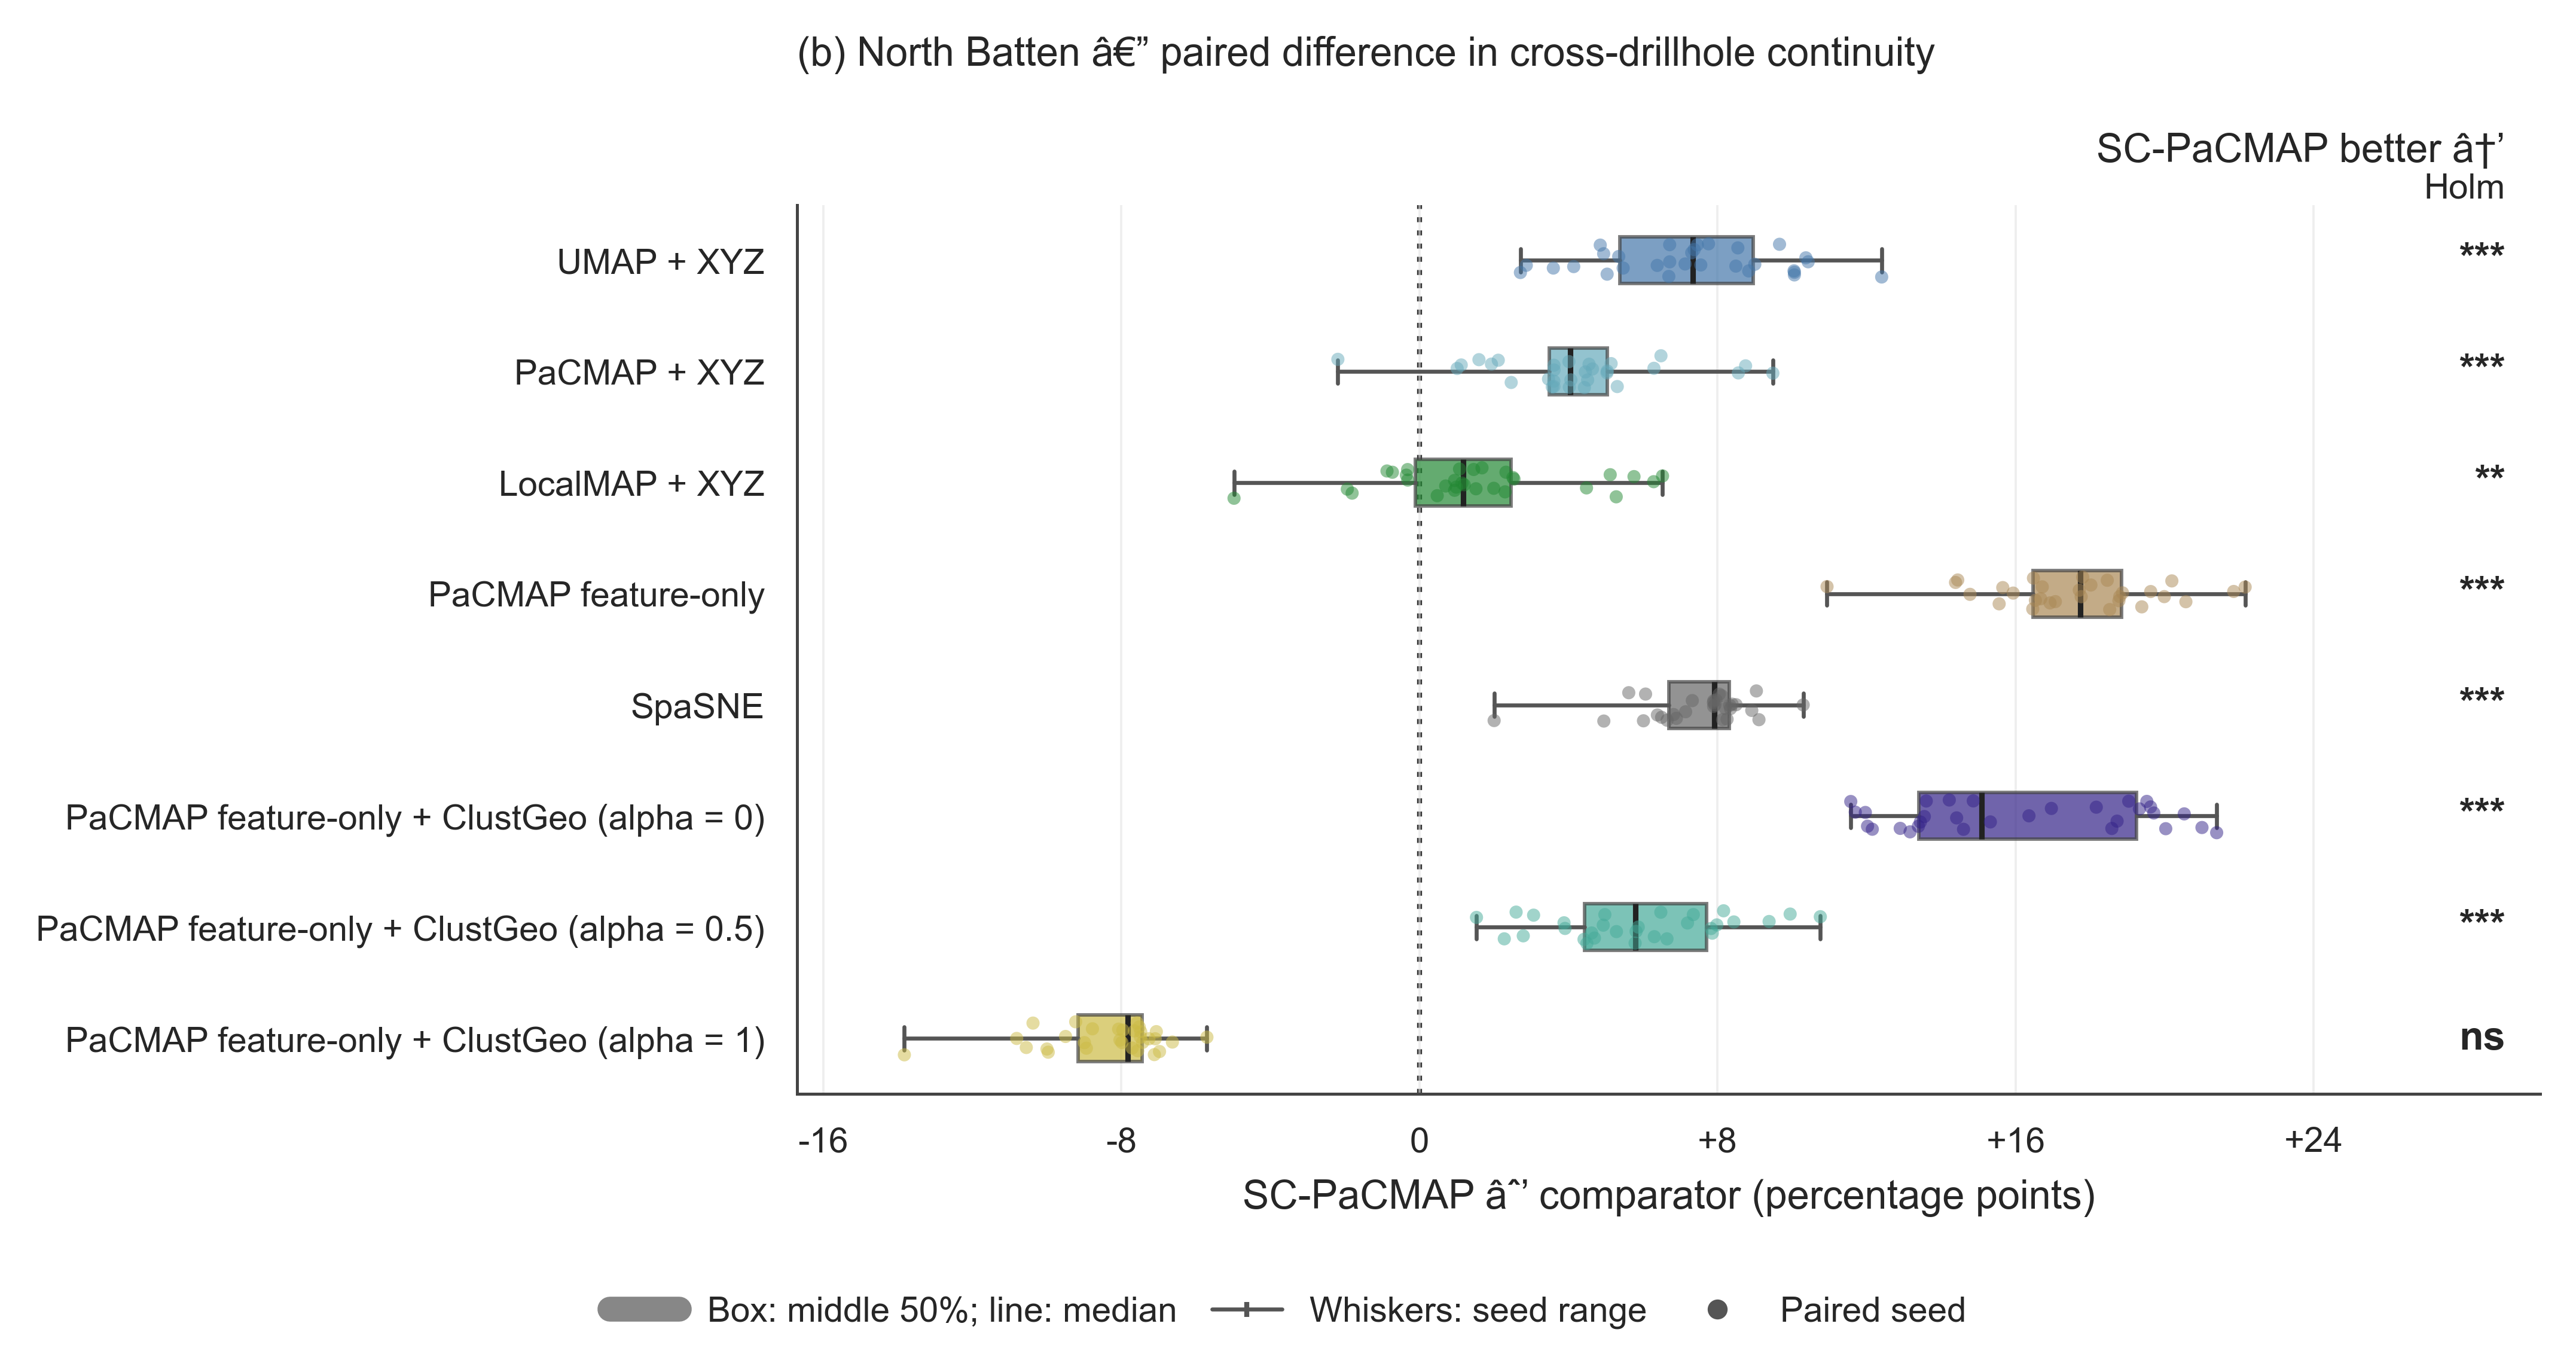

In [60]:
primary_method = 'SC-PaCMAP full graph'
paired = holdout.pivot(index='seed', columns='method', values='cross_hole_spatial')
expected_seeds = pd.Index(CROSS_GROUP_SEEDS, name='seed')
if not paired.index.equals(expected_seeds):
    raise ValueError('Expected exactly the configured 30 paired seeds; rerun the continuity cell.')
comparators = [method for method in METHODS if method != primary_method]
paired_deltas = paired[comparators].rsub(paired[primary_method], axis=0)
if not np.isfinite(paired_deltas.to_numpy()).all():
    raise ValueError('Continuity requires a finite value for every method and paired seed.')
# Recompute from the plotted data, so annotations cannot use a stale test table.
cross_hole_tests = paired_wilcoxon_table(holdout, 'cross_hole_spatial')
holm_p = cross_hole_tests.set_index('comparator').holm_p.reindex(comparators)

def holm_label(p):
    if p < .001: return '***'
    if p < .01: return '**'
    if p < .05: return '*'
    return 'ns'

fig, ax = plt.subplots(figsize=(7.1, 3.7), layout='constrained')
boxes = ax.boxplot(
    [paired_deltas[method].to_numpy() for method in comparators],
    vert=False, positions=np.arange(len(comparators)), widths=.42,
    patch_artist=True, whis=(0, 100), showfliers=False,
    medianprops=dict(color='#222222', linewidth=1.1),
    whiskerprops=dict(color='#555555', linewidth=.8),
    capprops=dict(color='#555555', linewidth=.8),
    boxprops=dict(edgecolor='#444444', linewidth=.7),
)
for row, (method, box) in enumerate(zip(comparators, boxes['boxes'])):
    box.set_facecolor(COLORS[method])
    box.set_alpha(.7)
    # Deterministic offsets keep rerunning the plot reproducible.
    offsets = np.random.default_rng(row).uniform(-.15, .15, len(paired_deltas))
    ax.scatter(paired_deltas[method], row + offsets, s=7, color=COLORS[method],
               alpha=.5, edgecolors='none', zorder=3)
    ax.text(.98, row, holm_label(holm_p.loc[method]),
            transform=ax.get_yaxis_transform(), ha='right', va='center',
            fontsize=8, fontweight='bold')
low = min(0., float(paired_deltas.min().min()))
high = max(0., float(paired_deltas.max().max()))
span = max(high - low, 1.)
ax.set_xlim(low - .08 * span, high + .22 * span)
ax.set_ylim(len(comparators) - .5, -.5)
ax.axvline(0, color='#333333', linestyle=':', linewidth=1., zorder=0)
ax.set_yticks(range(len(comparators)), [METHOD_LABELS[m] for m in comparators])
ax.set(xlabel='SC-PaCMAP âˆ’ comparator (percentage points)', ylabel='')
ax.set_title('(b) North Batten â€” paired difference in cross-drillhole continuity',
             loc='left', pad=28)
ax.text(.98, 1.04, 'SC-PaCMAP better â†’', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=8)
ax.text(.98, 1., 'Holm', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=7)
ax.xaxis.set_major_locator(MaxNLocator(6))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:+g}' if x else '0'))
ax.grid(axis='x', alpha=.6)
fig.legend(handles=[
    Line2D([], [], color='#555555', linewidth=5, alpha=.7, label='Box: middle 50%; line: median'),
    Line2D([], [], color='#555555', linewidth=.8, marker='|', label='Whiskers: seed range'),
    Line2D([], [], color='#555555', linestyle='None', marker='o', markersize=3, label='Paired seed'),
], loc='outside lower center', ncol=3, columnspacing=1.)
paper_show(fig)


In [61]:
# Export this section as data for later paper figures.
save_section('cross_group_plot', tables={'paired_differences': paired_deltas.rename_axis('seed').reset_index(),
             'holm_tests': cross_hole_tests})


Saved 2 data artifacts: C:\Users\weihong\Desktop\SC-PACMAP\sc-pacmap-reproducibility\results\notebook_exports\north_batten\cross_group_plot


WindowsPath('C:/Users/weihong/Desktop/SC-PACMAP/sc-pacmap-reproducibility/results/notebook_exports/north_batten/cross_group_plot')

**Figure caption.** (b) North Batten: paired difference in cross-drillhole continuity, SC-PaCMAP minus each comparator, over 30 matched algorithm seeds (0â€“29), in percentage points. Continuity uses 10 nearest neighbours outside each sample's own drillhole. Boxes show the interquartile range, centre lines the median, whiskers the full seed range, and dots the individual paired differences. These ranges describe algorithm variability, not confidence intervals or independent geological replication. The dotted zero line marks equal performance; positive differences favour SC-PaCMAP. Comparator colours match the spatialâ€“multivariate performance plane. Significance labels use the existing one-sided paired Wilcoxon tests with Holm correction across all active comparators within this dataset: * adjusted p < 0.05, ** p < 0.01, *** p < 0.001; ns otherwise. These are full-data diagnostics, not held-out-group predictions.
